# Práctica PCD: Asociación

**Objetivos:** el objetivo de esta práctica es experimentar y aprender mejor sobre modelos de asociación (FP-Growth, Apriori y ECLAT). En el proceso deberemos entender el problema, explorar y analizar los datos proporcionados mediante técnicas de EDA, probar los modelos e interpretar los resultados.

**Problema a resolver:** crear reglas de asociación entre productos, algo útil, por ejemplo, para crear sistemas de recomendación de compra. Como datos tenemos `bread_basket.xls`, que contiene transacciones de compras pasadas en formato tabular: el id de la compra, el artículo, la fecha, si era fin de semana y el momento del día.

**Entorno:** el notebook funciona igual en Jupyter local y en Google Colab. En Colab solo se instala una cosa: `mlxtend` 0.25, porque la 0.23.4 que trae Colab tiene un FP-Growth unas 200 veces más lento (recorre todas las transacciones en Python puro por cada itemset), lo que falsearía la comparativa de tiempos y memoria y hace que el experimento tarde cerca de 10 minutos. Se instala sin dependencias (`--no-deps`) para no actualizar pandas ni numpy; si la celda avisa de que ya estaba importada la versión antigua, hay que reiniciar el entorno de ejecución y volver a ejecutarla.

Usa `bread_basket.xls` (en realidad es un CSV) junto al notebook. Si no está, la celda siguiente lo descarga del dataset público [The Bread Basket](https://www.kaggle.com/datasets/mittalvasu95/the-bread-basket) de Kaggle, sin necesidad de cuenta ni token. Si la descarga falla en Colab, abre un diálogo para subirlo a mano, da igual con qué nombre.

In [1]:
import io
import subprocess
import sys
import urllib.request
import warnings
import zipfile
from importlib.metadata import version
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB and tuple(int(p) for p in version('mlxtend').split('.')[:2]) < (0, 24):
    if 'mlxtend' in sys.modules:
        raise RuntimeError('Old mlxtend already imported: restart the runtime and run this cell first')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'mlxtend==0.25.0'])

import mlxtend.frequent_patterns
warnings.filterwarnings('ignore', category=DeprecationWarning)

DATA_FILE = Path('bread_basket.xls')  
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/mittalvasu95/the-bread-basket'
KAGGLE_MEMBER = 'bread basket.csv'


def download_dataset(dest):
    print(f'{dest} not found: downloading it from Kaggle')
    with urllib.request.urlopen(KAGGLE_URL, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    dest.write_bytes(archive.read(KAGGLE_MEMBER))


if not DATA_FILE.exists():
    try:
        download_dataset(DATA_FILE)
    except Exception as exc:
        print(f'Kaggle download failed: {exc!r}')
        if IN_COLAB:
            from google.colab import files
            print('Upload the Bread Basket CSV manually (any file name)')
            uploaded = files.upload()
            if len(uploaded) != 1:
                raise FileNotFoundError(f'Expected exactly one uploaded file, got {len(uploaded)}')
            Path(next(iter(uploaded))).rename(DATA_FILE)

if not DATA_FILE.exists():
    raise FileNotFoundError(f'{DATA_FILE.resolve()} not found: place the dataset next to the notebook')

## EDA

In [2]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import matplotlib.pyplot as plt
import warnings
import time
import tracemalloc
import seaborn as sns



In [3]:
data = pd.read_csv(DATA_FILE)
print(data.shape)
data.head(10)

(20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [4]:
data.isna().sum()

Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB


In [6]:
data.nunique()

Transaction        9465
Item                 94
date_time          9182
period_day            4
weekday_weekend       2
dtype: int64

In [7]:
data['period_day'].unique()

<StringArray>
['morning', 'afternoon', 'evening', 'night']
Length: 4, dtype: str

La estructura de los datos es sencilla; igualmente obtenemos toda la información que podemos. `weekday_weekend` solo tiene dos valores (weekday y weekend) y `period_day` tiene 4 momentos del día ('morning', 'afternoon', 'evening', 'night'). El dataset no contiene nulos en ninguna de sus columnas. Existen un total de 94 ítems diferentes repartidos en 9465 transacciones, y el dataset tiene 20507 filas (varias filas corresponden a la misma transacción).

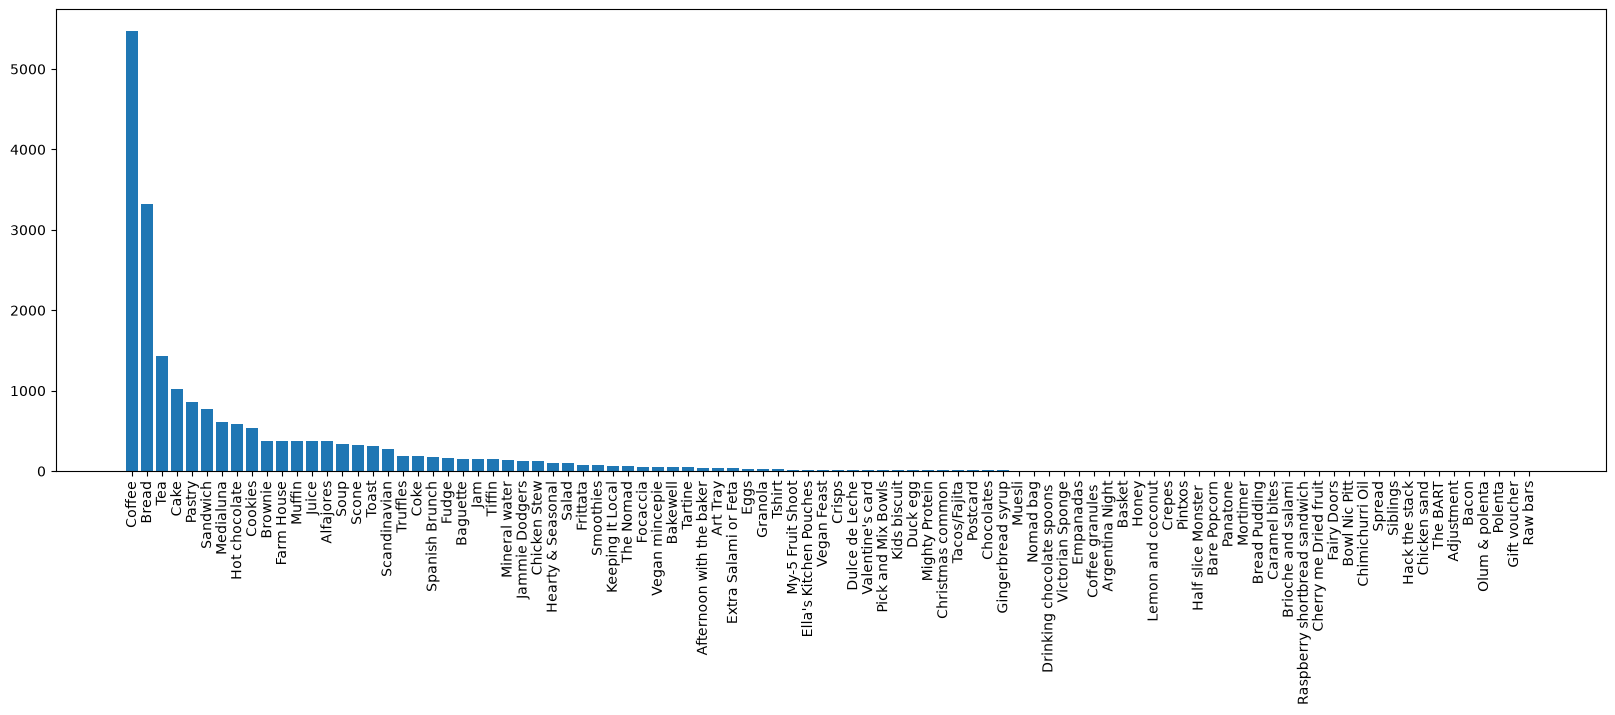

In [8]:
counts = data['Item'].value_counts()
plt.figure(figsize=(20, 6))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.show()



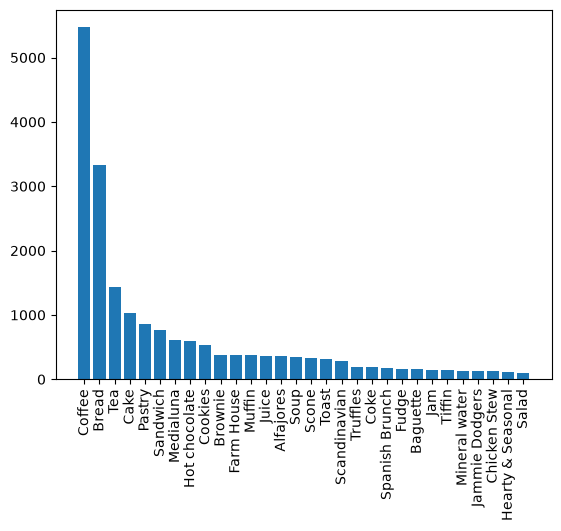

In [9]:
#plt.figure(figsize=(20, 6))
plt.bar(counts.index[:30], counts.values[:30])
plt.xticks(rotation=90)
plt.show()

Podemos ver que la frecuencia de casi todas las compras se concentra en unos pocos artículos.

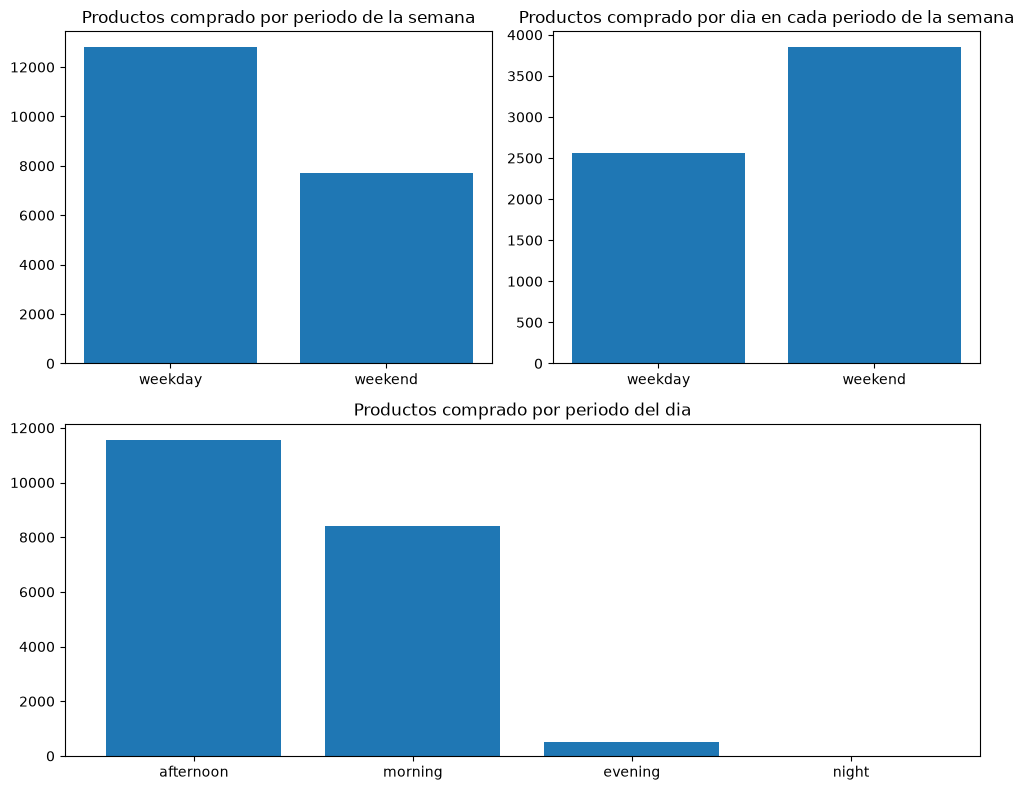

In [10]:
weekend_counts = data['weekday_weekend'].value_counts()
weekend_counts_norm = weekend_counts.astype(float)
weekend_counts_norm['weekend'] = weekend_counts_norm['weekend'] / 2
weekend_counts_norm['weekday'] = weekend_counts_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(weekend_counts.index, weekend_counts.values)
ax['left'].tick_params(axis='x', rotation=0)
ax['left'].set_title('Productos comprado por periodo de la semana')

ax['right'].bar(weekend_counts_norm.index, weekend_counts_norm.values)
ax['right'].tick_params(axis='x', rotation=0)
ax['right'].set_title('Productos comprado por dia en cada periodo de la semana')

period_counts=data['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x', rotation=0)
ax['bottom'].set_title('Productos comprado por periodo del dia')

plt.tight_layout()
plt.show()

In [11]:
transaction = data.groupby('Transaction').agg(
    Items=('Item', list),
    date_time=('date_time','first'),
    period_day=('period_day','first'),
    weekday_weekend=('weekday_weekend','first')
)

print(transaction.shape)
transaction.head()

(9465, 4)


,Items,date_time,period_day,weekday_weekend
Transaction,,,,
1,[Bread],30-10-2016 09:58,morning,weekend
2,"[Scandinavian, Scandinavian]",30-10-2016 10:05,morning,weekend
3,"[Hot chocolate, Jam, Cookies]",30-10-2016 10:07,morning,weekend
4,[Muffin],30-10-2016 10:08,morning,weekend
5,"[Coffee, Pastry, Bread]",30-10-2016 10:13,morning,weekend


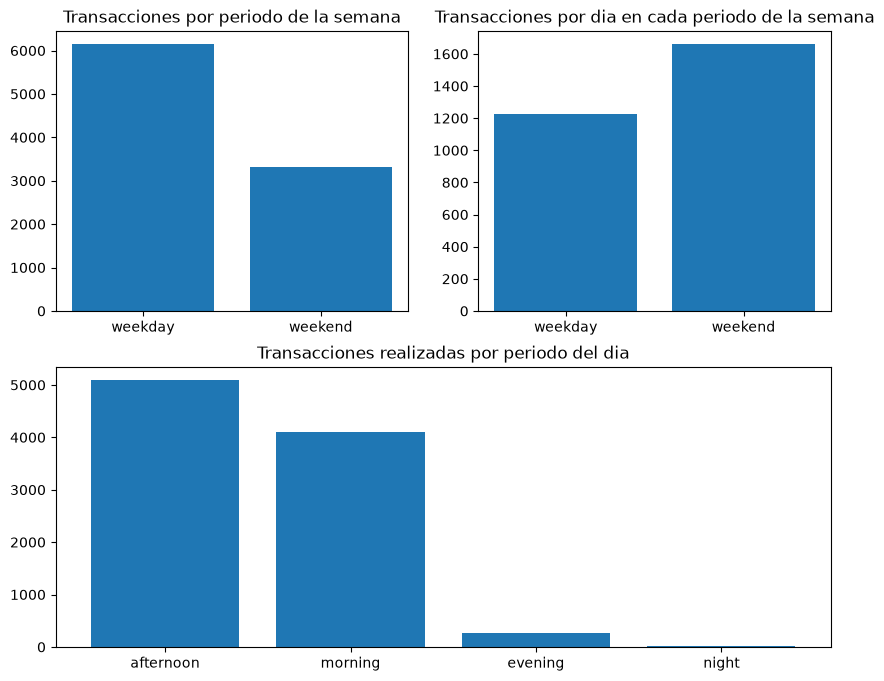

In [12]:
week_transactions = transaction['weekday_weekend'].value_counts()
week_transactions_norm = week_transactions.astype(float)
week_transactions_norm['weekend'] = week_transactions_norm['weekend'] / 2
week_transactions_norm['weekday'] = week_transactions_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(week_transactions.index, week_transactions.values)
ax['left'].tick_params(axis='x')
ax['left'].set_title('Transacciones por periodo de la semana')

ax['right'].bar(week_transactions_norm.index, week_transactions_norm.values)
ax['right'].tick_params(axis='x')
ax['right'].set_title('Transacciones por dia en cada periodo de la semana')


period_counts=transaction['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x')
ax['bottom'].set_title('Transacciones realizadas por periodo del dia')

plt.show() 

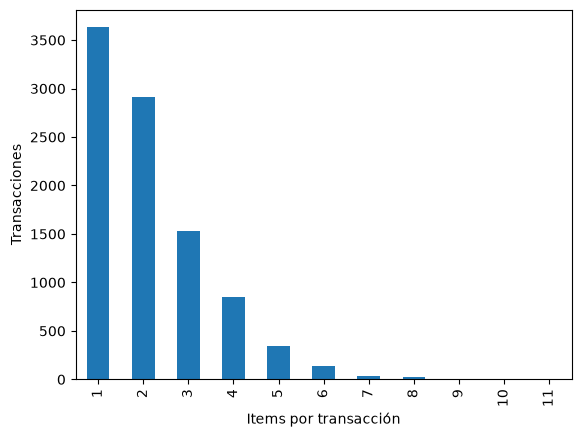

In [13]:

n_items = transaction['Items'].str.len()

n_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items por transacción')
plt.ylabel('Transacciones')
plt.show()

Repeated items within a transaction: 1620
Mean basket size (raw / distinct): 2.17 / 2.00
Single-item transactions: 41.7%


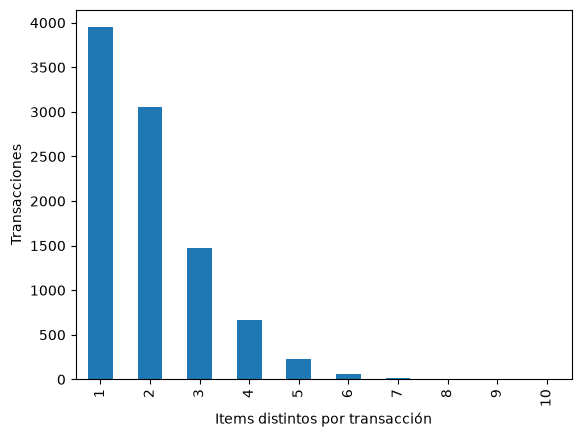

In [14]:
dup_items = data.duplicated(['Transaction', 'Item']).sum()
n_unique_items = transaction['Items'].apply(lambda items: len(set(items)))

print(f'Repeated items within a transaction: {dup_items}')
print(f'Mean basket size (raw / distinct): {n_items.mean():.2f} / {n_unique_items.mean():.2f}')
print(f'Single-item transactions: {(n_unique_items == 1).mean():.1%}')

n_unique_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items distintos por transacción')
plt.ylabel('Transacciones')
plt.show()

Hay 1620 items repetidos dentro de la misma transacción, que inflan el tamaño de cesta (2.17 → 2.00 items distintos de media). El 41.7 % de las transacciones tienen un solo producto: no aportan co-ocurrencias, pero sí cuentan en el denominador del soporte.

Item
Coffee           0.478
Bread            0.327
Tea              0.143
Cake             0.104
Pastry           0.086
Sandwich         0.072
Medialuna        0.062
Hot chocolate    0.058
Cookies          0.054
Brownie          0.040
Name: count, dtype: float64

Items with support >= 1%: 30 / 94
Items with support >= 2%: 19 / 94
Items with support >= 5%: 9 / 94


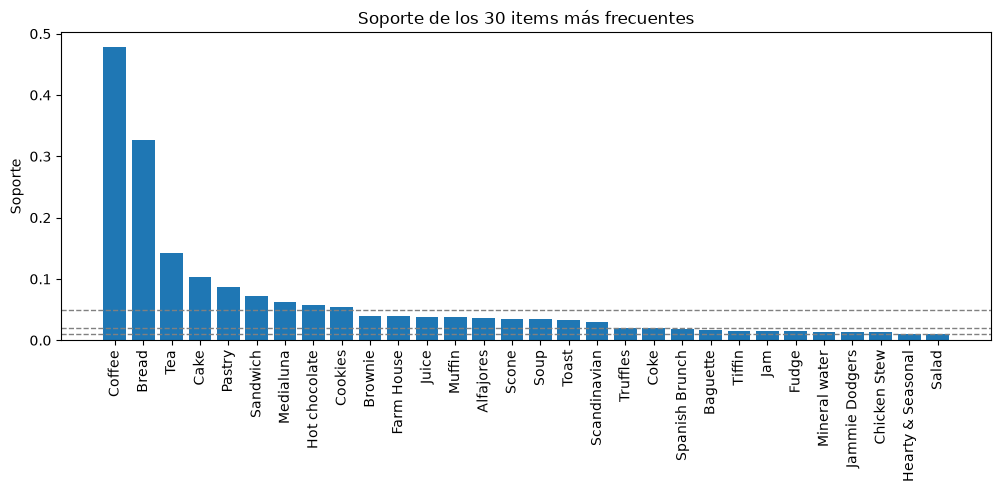

In [15]:

item_support = (
    data.drop_duplicates(['Transaction', 'Item'])['Item'].value_counts()
    / data['Transaction'].nunique()
)
print(item_support.head(10).round(3))
print()
for threshold in [0.01, 0.02, 0.05]:
    print(f'Items with support >= {threshold:.0%}: {(item_support >= threshold).sum()} / {len(item_support)}')

plt.figure(figsize=(12, 4))
plt.bar(item_support.index[:30], item_support.values[:30])
for threshold in [0.01, 0.02, 0.05]:
    plt.axhline(threshold, linestyle='--', linewidth=1, color='gray')
plt.xticks(rotation=90)
plt.ylabel('Soporte')
plt.title('Soporte de los 30 items más frecuentes')
plt.show()

El café y el pan están en casi la mitad y un tercio de las compras, respectivamente. Esto significa que muchas reglas de asociación pueden llegar a tenerlos como consecuente aunque no sean demasiado informativas. Solo 30 de los 94 ítems llegan al 1 % de soporte.

In [16]:
print(item_support.tail(15).round(4))
print()
print(data['period_day'].value_counts())

Item
Cherry me Dried fruit    0.0003
Fairy Doors              0.0002
Bowl Nic Pitt            0.0002
Chimichurri Oil          0.0002
Spread                   0.0002
Siblings                 0.0002
Hack the stack           0.0002
Chicken sand             0.0001
The BART                 0.0001
Adjustment               0.0001
Bacon                    0.0001
Olum & polenta           0.0001
Polenta                  0.0001
Gift voucher             0.0001
Raw bars                 0.0001
Name: count, dtype: float64

period_day
afternoon    11569
morning       8404
evening        520
night           14
Name: count, dtype: int64


Date range: 2016-10-30 09:58:00 -> 2017-04-09 15:04:00 (159 days)


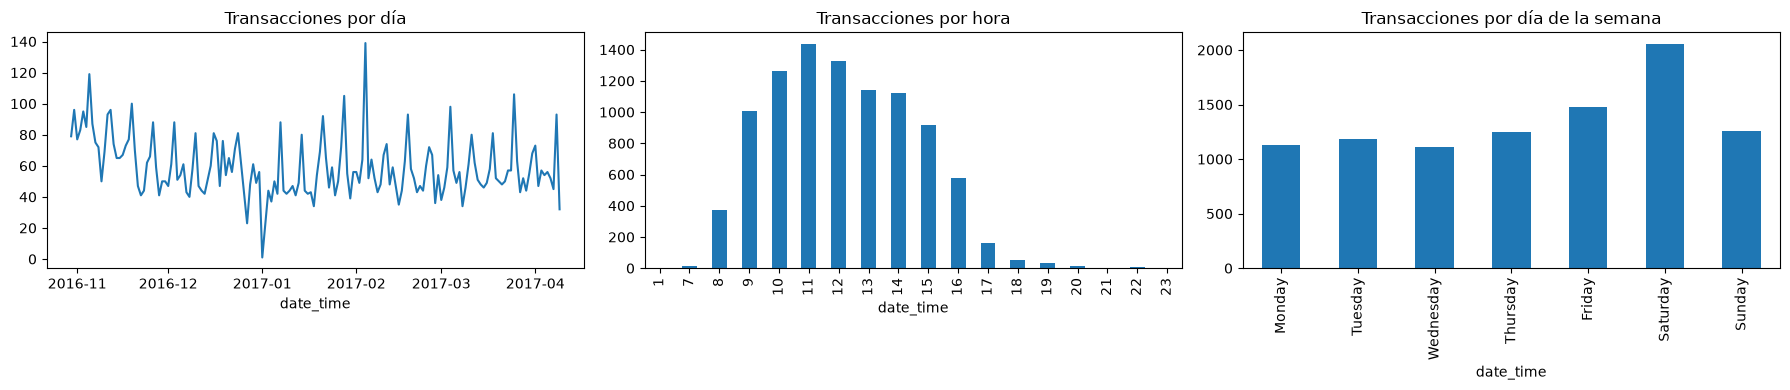

In [17]:
tx_datetime = pd.to_datetime(transaction['date_time'], format='%d-%m-%Y %H:%M')
print(f'Date range: {tx_datetime.min()} -> {tx_datetime.max()} ({tx_datetime.dt.date.nunique()} days)')

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

tx_datetime.dt.date.value_counts().sort_index().plot(ax=ax[0])
ax[0].set_title('Transacciones por día')

tx_datetime.dt.hour.value_counts().sort_index().plot(kind='bar', ax=ax[1])
ax[1].set_title('Transacciones por hora')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
tx_datetime.dt.day_name().value_counts().reindex(day_order).plot(kind='bar', ax=ax[2])
ax[2].set_title('Transacciones por día de la semana')

plt.tight_layout()
plt.show()

 159 días (oct-2016 - abr-2017), ~60 transacciones al día. La actividad se concentra entre las 9h y las 16h y el sábado es el día más fuerte.

In [18]:
te = TransactionEncoder()
te_ary = te.fit(transaction['Items']).transform(transaction['Items'])
df = pd.DataFrame(te_ary, columns=te.columns_)
df

,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9460,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9461,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
9462,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9463,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


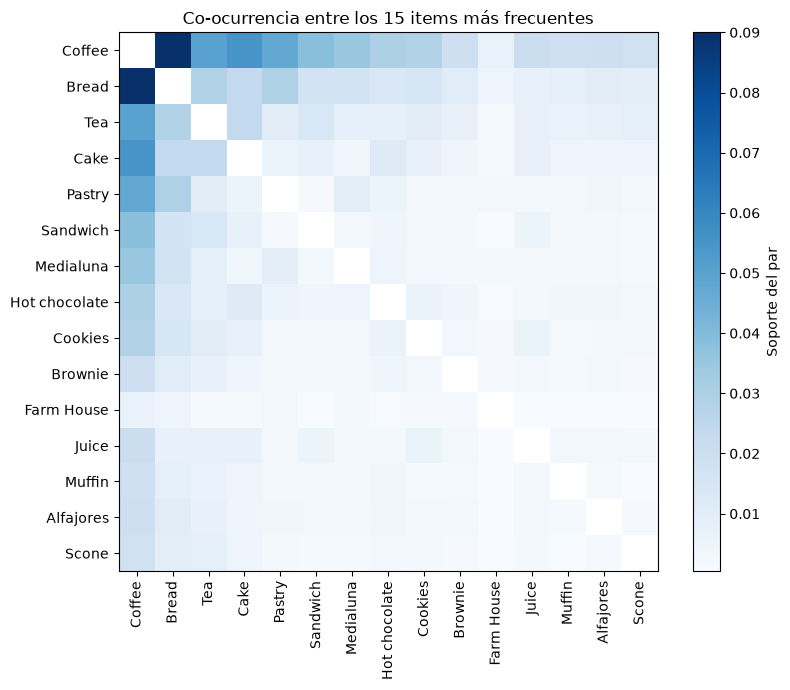

Coffee & Bread -> observed: 0.090 | expected if independent: 0.157 | lift: 0.58


In [19]:

top_items = item_support.index[:15]
top_df = df[top_items].astype(int)
pair_support = (top_df.T @ top_df) / len(df)
pair_support = pair_support.mask(np.eye(len(top_items), dtype=bool))

plt.figure(figsize=(9, 7))
plt.imshow(pair_support, cmap='Blues')
plt.colorbar(label='Soporte del par')
plt.xticks(range(len(top_items)), top_items, rotation=90)
plt.yticks(range(len(top_items)), top_items)
plt.title('Co-ocurrencia entre los 15 items más frecuentes')
plt.show()


observed = pair_support.loc['Coffee', 'Bread']
expected = item_support['Coffee'] * item_support['Bread']
print(f'Coffee & Bread -> observed: {observed:.3f} | expected if independent: {expected:.3f} | lift: {observed / expected:.2f}')

Los pares más frecuentes casi siempre incluyen Coffee (Bread, Cake, Tea, Pastry).Coffee y Bread aparece menos  de lo esperado por azar (lift < 1). 

## Preprocesado

Varias transacciones tienen elementos repetidos. Aunque esto no debería afectar a los algoritmos (solo miran si un producto está o no en la cesta), eliminamos estos duplicados. También limpiamos los nombres de algunos productos que acaban en un espacio (`'Coffee granules '`, `'Drinking chocolate spoons '`, `'Half slice Monster '`). Adicionalmente, eliminamos los registros que no corresponden a productos: apuntes administrativos (`Adjustment`, `Gift voucher`) y eventos (`Argentina Night`, `Afternoon with the baker`). El merchandising y los regalos (`Tshirt`, `Postcard`…) se mantienen porque son ventas reales.

Los tickets que solo contenían registros excluidos desaparecen. Los tickets de un solo producto se mantienen, porque son compras reales y cuentan en el denominador del soporte. El EDA anterior describe el dataset original; a partir de aquí se usa el preprocesado.

In [20]:
NON_PRODUCT_ITEMS = ['Adjustment', 'Gift voucher', 'Afternoon with the baker', 'Argentina Night']

raw_rows, raw_baskets, raw_items = len(data), data['Transaction'].nunique(), data['Item'].nunique()
data = data.assign(Item=data['Item'].str.strip())
excluded_rows = data['Item'].isin(NON_PRODUCT_ITEMS)
print(data.loc[excluded_rows, 'Item'].value_counts().to_string(), '\n')
data = data[~excluded_rows]
duplicated_rows = data.duplicated(['Transaction', 'Item'])
data = data[~duplicated_rows].reset_index(drop=True)

print(f'Rows: {raw_rows} -> {len(data)} ({excluded_rows.sum()} non-product, {duplicated_rows.sum()} repeated within a ticket)')
print(f"Baskets: {raw_baskets} -> {data['Transaction'].nunique()} (emptied by the exclusion)")
print(f"Items: {raw_items} -> {data['Item'].nunique()}")

# Rebuild the basket table and the one-hot matrix from the clean data
transaction = data.groupby('Transaction').agg(
    Items=('Item', list),
    date_time=('date_time', 'first'),
    period_day=('period_day', 'first'),
    weekday_weekend=('weekday_weekend', 'first')
)
te = TransactionEncoder()
df = pd.DataFrame(te.fit(transaction['Items']).transform(transaction['Items']), columns=te.columns_)
df.shape

Item
Afternoon with the baker    44
Argentina Night              7
Adjustment                   1
Gift voucher                 1 

Rows: 20507 -> 18835 (53 non-product, 1619 repeated within a ticket)
Baskets: 9465 -> 9430 (emptied by the exclusion)
Items: 94 -> 90


(9430, 90)

## Modelos 

### 1. Algoritmos
- **Apriori** (Agrawal y Srikant, 1994): busca los itemsets frecuentes por niveles, generando los candidatos de tamaño k + 1 a partir de los frecuentes de tamaño k.
- **FP-Growth** (Han, Pei y Yin, 2000): comprime las transacciones en un árbol de prefijos (FP-tree) y hace crecer los patrones sin generar candidatos.
- **ECLAT** (Zaki, 2000): representa cada producto por la lista de transacciones que lo contienen y calcula el soporte cruzando esas listas, en profundidad.

Los tres son exactos: encuentran los mismos itemsets frecuentes, y las reglas se generan después con `association_rules`. `mlxtend` no incluye ECLAT, así que lo implementamos nosotros (en Python puro).

In [21]:


def eclat(df, min_support=0.5, use_colnames=True, max_len=None):
    n_transactions = len(df)
    min_count = min_support * n_transactions
    tidsets = [(item, df[item].to_numpy()) for item in df.columns if df[item].sum() >= min_count]
    results = []

    def extend(prefix, prefix_mask, candidates):
        for i, (item, mask) in enumerate(candidates):
            new_mask = mask if prefix_mask is None else prefix_mask & mask
            count = new_mask.sum()
            if count < min_count:
                continue
            itemset = prefix + (item,)
            results.append((count / n_transactions, frozenset(itemset)))
            if max_len is None or len(itemset) < max_len:
                extend(itemset, new_mask, candidates[i + 1:])

    extend((), None, tidsets)
    return pd.DataFrame(results, columns=['support', 'itemsets'])


algorithms = {'Apriori': apriori, 'FP-Growth': fpgrowth, 'ECLAT': eclat}

### 2. Diseño del experimento
Para medir el funcionamiento de los 3 algoritmos los probamos en diferentes situaciones (configuraciones): cambiamos el soporte y la confianza que usamos para generar las reglas (3 algoritmos × 6 niveles de soporte × 4 niveles de confianza = 72 configuraciones distintas). La confianza no interviene en la búsqueda de itemsets, solo en la generación de reglas.

Realizamos 8 ejecuciones por cada combinación de algoritmo y soporte: 7 de ellas para medir el tiempo de forma insesgada, ya que puede haber caídas de rendimiento en la máquina que ejecuta (cogemos el mínimo), y la octava para medir el uso de memoria (`tracemalloc` ralentiza el código, por eso va aparte).

Después comparamos la efectividad del modelo: número de reglas, número de reglas útiles (lift ≥ 1.2), etc. Una vez escojamos el modelo óptimo, evaluaremos las reglas de salida y su importancia.

In [22]:
SUPPORT_GRID = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
CONFIDENCE_GRID = [0.1, 0.25, 0.5, 0.7]
USEFUL_LIFT = 1.2
N_RUNS = 7
QUALITY_METRICS = ['support', 'confidence', 'lift', 'conviction', 'leverage']


def measure_runtime(algorithm, min_support, n_runs=N_RUNS):
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        itemsets = algorithm(df, min_support=min_support, use_colnames=True)
        times.append(time.perf_counter() - start)
    return min(times) * 1000, itemsets


def measure_memory(algorithm, min_support):
    tracemalloc.start()
    algorithm(df, min_support=min_support, use_colnames=True)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024 ** 2


def build_rules(itemsets, min_confidence, n_runs=N_RUNS):
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        rules = association_rules(itemsets, num_itemsets=len(df), metric='confidence', min_threshold=min_confidence)
        times.append(time.perf_counter() - start)
    rules['conviction'] = rules['conviction'].replace(np.inf, np.nan)
    return min(times) * 1000, rules

In [23]:
experiment, all_rules = [], {}
for min_support in SUPPORT_GRID:
    for name, algorithm in algorithms.items():
        mining_ms, itemsets = measure_runtime(algorithm, min_support)
        memory_mb = measure_memory(algorithm, min_support)
        for min_confidence in CONFIDENCE_GRID:
            rules_ms, rules = build_rules(itemsets, min_confidence)
            all_rules[(name, min_support, min_confidence)] = rules
            n_useful = (rules['lift'] >= USEFUL_LIFT).sum()
            experiment.append({
                'algorithm': name,
                'min_support': min_support,
                'min_confidence': min_confidence,
                'mining_ms': mining_ms,
                'rules_ms': rules_ms,
                'total_ms': mining_ms + rules_ms,
                'memory_mb': memory_mb,
                'n_itemsets': len(itemsets),
                'n_rules': len(rules),
                'n_useful_rules': n_useful,
                'useful_ratio': n_useful / len(rules) if len(rules) else np.nan,
                **{f'mean_{metric}': rules[metric].mean() for metric in QUALITY_METRICS},
            })
experiment = pd.DataFrame(experiment)
experiment.round(3)

,algorithm,min_support,min_confidence,mining_ms,rules_ms,total_ms,memory_mb,n_itemsets,n_rules,n_useful_rules,useful_ratio,mean_support,mean_confidence,mean_lift,mean_conviction,mean_leverage
0,Apriori,0.001,0.10,63.104,14.118,77.222,44.182,470,518,278,0.537,0.005,0.293,2.113,1.104,-0.000
1,Apriori,0.001,0.25,63.104,8.706,71.811,44.182,470,226,88,0.389,0.005,0.462,1.929,1.210,-0.000
2,Apriori,0.001,0.50,63.104,8.852,71.956,44.182,470,96,56,0.583,0.005,0.612,1.285,1.481,0.001
3,Apriori,0.001,0.70,63.104,8.135,71.239,44.182,470,14,14,1.000,0.003,0.792,1.649,2.702,0.001
4,FP-Growth,0.001,0.10,87.970,8.800,96.770,0.946,470,518,278,0.537,0.005,0.293,2.113,1.104,-0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,FP-Growth,0.050,0.70,51.726,1.273,52.999,0.071,12,0,0,NaN,NaN,NaN,NaN,NaN,NaN
68,ECLAT,0.050,0.10,7.658,4.168,11.826,0.106,12,6,0,0.000,0.065,0.260,0.800,0.902,-0.027
69,ECLAT,0.050,0.25,7.658,4.180,11.838,0.106,12,3,0,0.000,0.065,0.384,0.800,0.872,-0.027
70,ECLAT,0.050,0.50,7.658,3.964,11.622,0.106,12,1,0,0.000,0.055,0.527,1.097,1.099,0.005


In [24]:
def rule_set(rules):
    return set(zip(rules['antecedents'], rules['consequents'], rules['support'].round(10)))


same_rules = all(
    rule_set(all_rules[(name, s, c)]) == rule_set(all_rules[('Apriori', s, c)])
    for name in algorithms for s in SUPPORT_GRID for c in CONFIDENCE_GRID
)
print(f'Same rules for every algorithm in all {len(SUPPORT_GRID) * len(CONFIDENCE_GRID)} threshold combinations: {same_rules}')

Same rules for every algorithm in all 24 threshold combinations: True


Vemos que los algoritmos están generando exáctamente las mismas reglas para todas la configuraciones. Eso significa que lo que cambia entre modelos es la eficiencia, mientras que la eficacia depende de los umbrales

### 3. Visualización de resultados

#### 3.1 Eficiencia

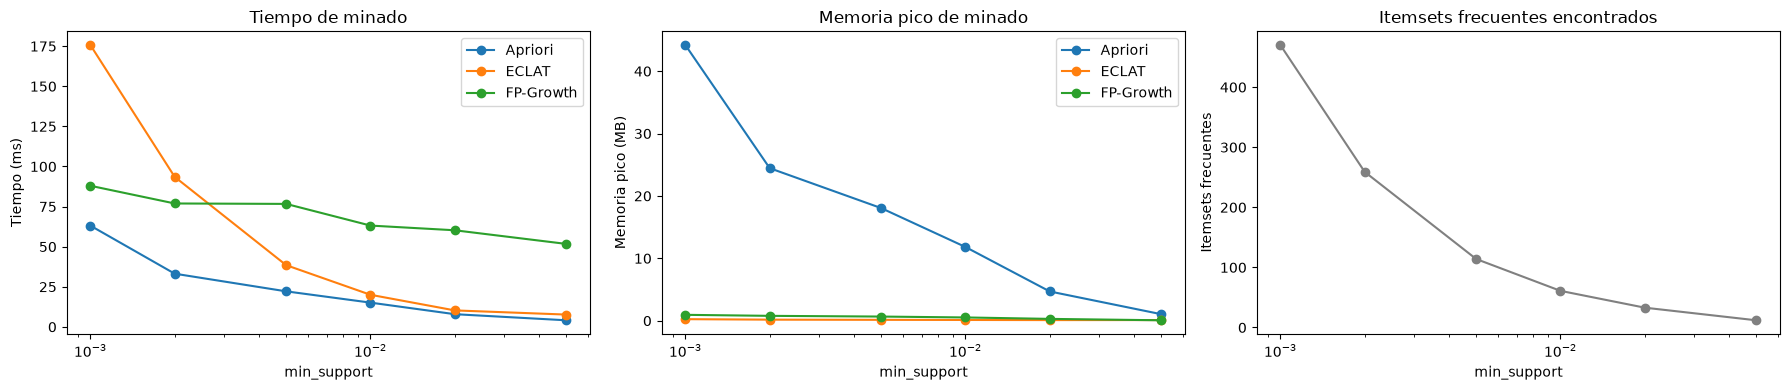

mining_ms                   memory_mb                
algorithm     Apriori   ECLAT FP-Growth   Apriori ECLAT FP-Growth
min_support                                                      
0.001           63.10  175.70     87.97     44.18  0.25      0.95
0.002           33.15   93.52     76.94     24.45  0.17      0.78
0.005           22.15   38.47     76.67     18.06  0.14      0.67
0.010           15.11   20.00     63.16     11.82  0.12      0.53
0.020            7.90   10.26     60.23      4.69  0.10      0.30
0.050            4.09    7.66     51.73      1.05  0.11      0.07

In [25]:
efficiency = experiment.drop_duplicates(['algorithm', 'min_support'])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, group in efficiency.groupby('algorithm'):
    ax[0].plot(group['min_support'], group['mining_ms'], marker='o', label=name)
    ax[1].plot(group['min_support'], group['memory_mb'], marker='o', label=name)
ax[2].plot(efficiency['min_support'].unique(), efficiency.drop_duplicates('min_support')['n_itemsets'], marker='o', color='gray')

for axis, ylabel, title in zip(
    ax,
    ['Tiempo (ms)', 'Memoria pico (MB)', 'Itemsets frecuentes'],
    ['Tiempo de minado', 'Memoria pico de minado', 'Itemsets frecuentes encontrados'],
):
    axis.set_xscale('log')
    axis.set_xlabel('min_support')
    axis.set_ylabel(ylabel)
    axis.set_title(title)
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

efficiency.pivot(index='min_support', columns='algorithm', values=['mining_ms', 'memory_mb']).round(2)

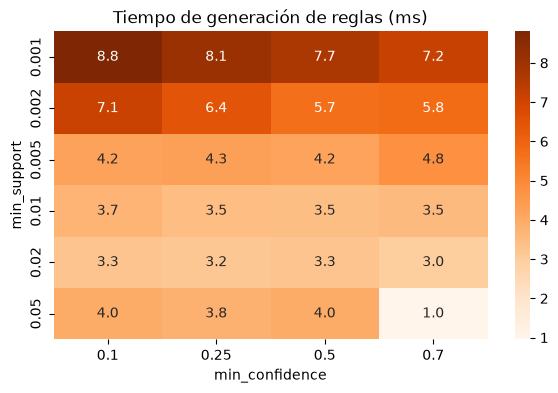

In [26]:
rules_time = experiment.groupby(['min_support', 'min_confidence'])['rules_ms'].median().unstack()

plt.figure(figsize=(7, 4))
sns.heatmap(rules_time, annot=True, fmt='.1f', cmap='Oranges')
plt.title('Tiempo de generación de reglas (ms)')
plt.show()

**Lectura.** Apriori es el más rápido con soportes medios y altos, pero el que más memoria usa (hasta 44 MB con soporte 0.001), porque genera y evalúa candidatos. FP-Growth tiene un coste fijo alto (unos 40–70 ms) que apenas depende del soporte. ECLAT usa muy poca memoria (menos de 0.25 MB), pero al ser Python puro se vuelve el más lento con soportes muy bajos. El número de itemsets crece muy rápido al bajar el soporte (12 con 0.05 frente a 470 con 0.001). Generar las reglas solo cuesta unos milisegundos en todos los casos: el coste está en la búsqueda de itemsets.

#### 3.2 Efectividad

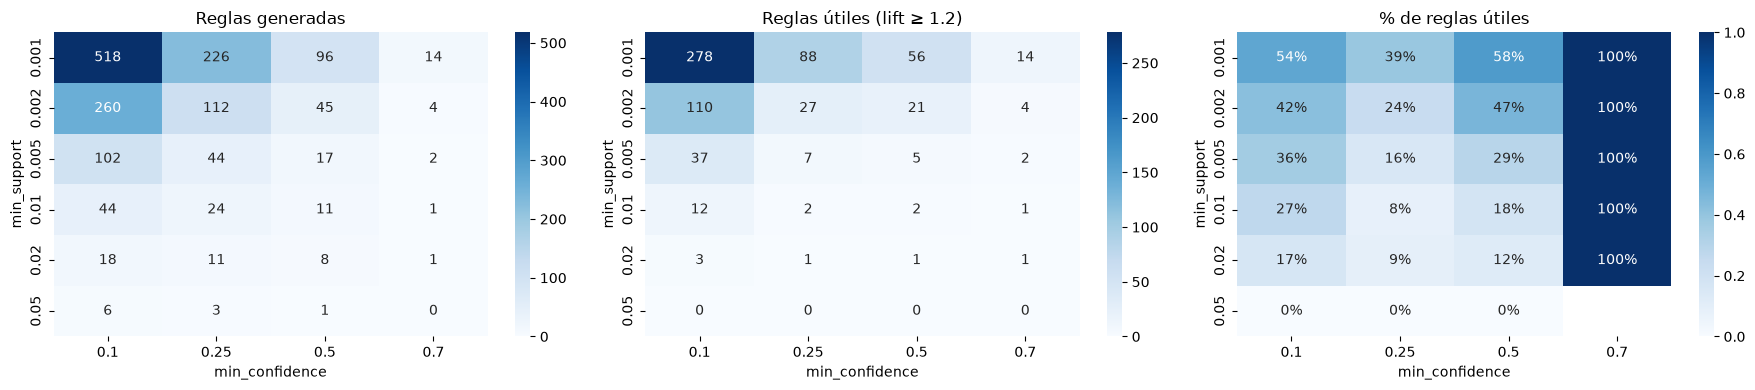

In [27]:
quality = experiment[experiment['algorithm'] == 'Apriori'].set_index(['min_support', 'min_confidence'])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for axis, column, title, fmt in zip(
    ax,
    ['n_rules', 'n_useful_rules', 'useful_ratio'],
    ['Reglas generadas', f'Reglas útiles (lift ≥ {USEFUL_LIFT})', '% de reglas útiles'],
    ['d', 'd', '.0%'],
):
    sns.heatmap(quality[column].unstack(), annot=True, fmt=fmt, cmap='Blues', ax=axis)
    axis.set_title(title)
plt.tight_layout()
plt.show()

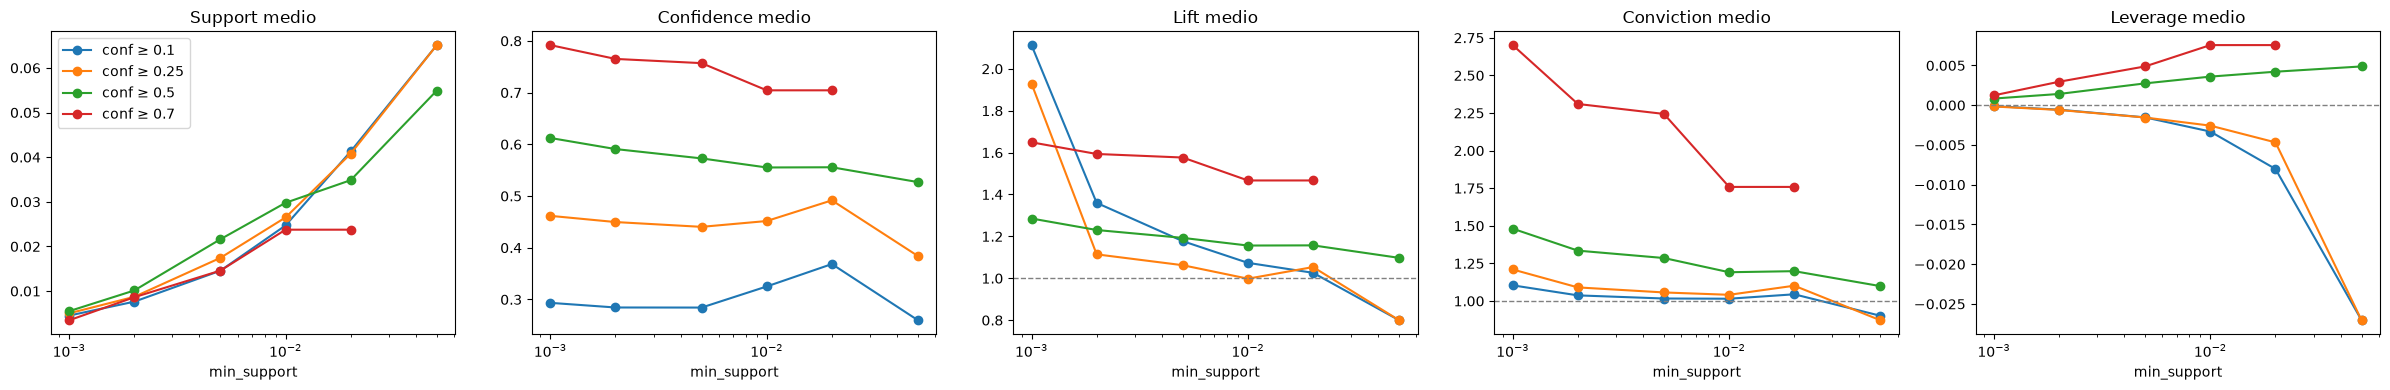

In [28]:
fig, ax = plt.subplots(1, 5, figsize=(24, 4))
for axis, metric in zip(ax, QUALITY_METRICS):
    for min_confidence, group in quality.reset_index().groupby('min_confidence'):
        axis.plot(group['min_support'], group[f'mean_{metric}'], marker='o', label=f'conf ≥ {min_confidence}')
    axis.set_xscale('log')
    axis.set_xlabel('min_support')
    axis.set_title(f'{metric.capitalize()} medio')
ax[2].axhline(1, linestyle='--', color='gray', linewidth=1)
ax[3].axhline(1, linestyle='--', color='gray', linewidth=1)
ax[4].axhline(0, linestyle='--', color='gray', linewidth=1)
ax[0].legend()
plt.tight_layout()
plt.show()

**Lectura.** Al bajar el soporte, el número de reglas crece muy rápido (de 6 a 518 con confianza 0.1). Subir la confianza elimina reglas, pero no las hace más útiles: con soporte 0.005, el 36 % de las reglas tiene lift ≥ 1.2 con confianza 0.1 y solo el 16 % con confianza 0.25. Con confianza 0.7 todas son útiles, pero apenas quedan reglas (14 como máximo). En las medias, la confianza y la conviction suben con el umbral de confianza, mientras que el lift medio no sigue un patrón claro.

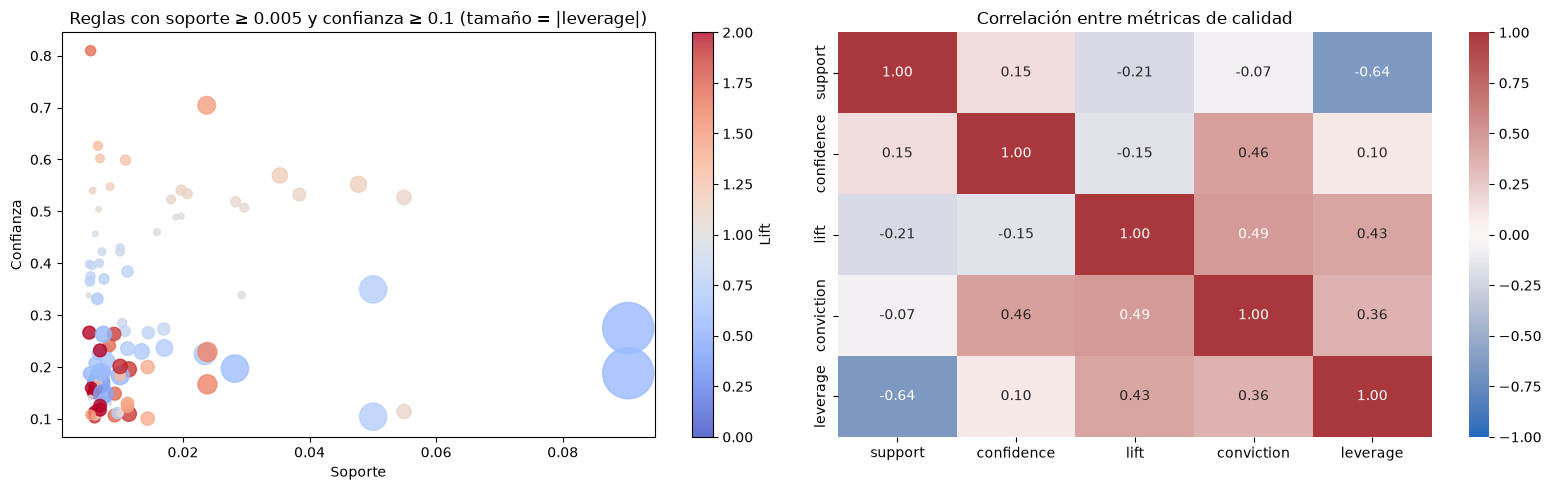

In [29]:
REFERENCE_CONFIG = ('Apriori', 0.005, 0.1)
reference_rules = all_rules[REFERENCE_CONFIG]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
points = ax[0].scatter(reference_rules['support'], reference_rules['confidence'],
                       c=reference_rules['lift'], s=reference_rules['leverage'].abs() * 20000 + 10,
                       cmap='coolwarm', vmin=0, vmax=2, alpha=0.8)
fig.colorbar(points, ax=ax[0], label='Lift')
ax[0].set_xlabel('Soporte')
ax[0].set_ylabel('Confianza')
ax[0].set_title(f'Reglas con soporte ≥ {REFERENCE_CONFIG[1]} y confianza ≥ {REFERENCE_CONFIG[2]} (tamaño = |leverage|)')

sns.heatmap(reference_rules[QUALITY_METRICS].corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Correlación entre métricas de calidad')
plt.tight_layout()
plt.show()

In [30]:
useful_rules = reference_rules[reference_rules['lift'] >= USEFUL_LIFT].sort_values('lift', ascending=False).copy()
useful_rules['antecedents'] = useful_rules['antecedents'].apply(lambda s: ', '.join(sorted(s)))
useful_rules['consequents'] = useful_rules['consequents'].apply(lambda s: ', '.join(sorted(s)))
useful_rules[['antecedents', 'consequents'] + QUALITY_METRICS].head(15).round(3)

,antecedents,consequents,support,confidence,lift,conviction,leverage
53,Coke,Sandwich,0.005,0.266,3.693,1.265,0.004
56,Juice,Cookies,0.006,0.159,2.910,1.124,0.004
57,Cookies,Juice,0.006,0.113,2.910,1.083,0.004
92,"Coffee, Hot chocolate",Cake,0.007,0.232,2.227,1.167,0.004
67,Soup,Sandwich,0.006,0.160,2.212,1.104,0.003
95,Hot chocolate,"Cake, Coffee",0.007,0.118,2.144,1.071,0.004
93,"Cake, Coffee",Hot chocolate,0.007,0.125,2.144,1.077,0.004
60,Juice,Sandwich,0.006,0.151,2.090,1.093,0.003
97,"Coffee, Tea",Cake,0.010,0.201,1.931,1.121,0.005
54,Hot chocolate,Cookies,0.006,0.103,1.891,1.054,0.003


**Lectura.** Con soporte 0.005 y confianza 0.1 (102 reglas, 37 útiles), la confianza y el lift apenas están relacionados (correlación −0.15): una confianza alta no implica una asociación fuerte. Las reglas con más lift (Coke → Sandwich, Juice ↔ Cookies, Hot chocolate ↔ Cake) tienen confianzas bajas, del 10–27 %.

### 4. Análisis en profundidad de las reglas

#### 4.1 Elección del soporte mínimo y del modelo


**Soporte.** Primero debemos escoger el soporte. Un soporte bajo encuentra más asociaciones, incluidas las de productos poco frecuentes (Liu, Hsu y Ma, 1999), y también más reglas apoyadas en pocas cestas, que podrían haber ocurrido por puro azar (Webb, 2007). Por ello probamos con diversos valores de soporte y medimos la utilidad de las reglas que genera cada uno.

Las reglas pasan por tres filtros: el soporte mínimo, un lift ≥ 1.2 y después el test de Fisher corregido por Benjamini-Hochberg (Benjamini y Hochberg, 1995). Nuestro criterio es la validación con datos reservados (Webb, 2007): solo usamos el periodo de train (el 70 % de las primeras transacciones, en orden temporal), que dividimos a su vez en una parte de ajuste, donde se generan las reglas y se pasan por los filtros, y otra de validación, donde repetimos el test de Fisher + BH sobre esas reglas con cestas que no se usaron para descubrirlas. Escogemos el soporte con mayor tasa de confirmación. El 30 % final queda reservado para la sección 4.6.

In [31]:
from scipy.stats import fisher_exact, false_discovery_control, spearmanr


def basket_mask(matrix, itemset):
    return matrix[list(itemset)].all(axis=1).to_numpy()


def contingency_table(matrix, antecedent, consequent):
    a, c = basket_mask(matrix, antecedent), basket_mask(matrix, consequent)
    return [[(a & c).sum(), (a & ~c).sum()], [(~a & c).sum(), (~a & ~c).sum()]]


def pair_lift(matrix, antecedent, consequent):
    a, c = basket_mask(matrix, antecedent), basket_mask(matrix, consequent)
    return (a & c).mean() / (a.mean() * c.mean()) if a.any() and c.any() else np.nan


def join_items(itemset):
    return ', '.join(sorted(itemset))


def is_single_pair(rules):
    return (rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)


def collapse_directions(rules):
    pairs = [frozenset([a, c]) for a, c in zip(rules['antecedents'], rules['consequents'])]
    return (rules.assign(pair=pairs)
            .sort_values('confidence', ascending=False)
            .drop_duplicates('pair')
            .sort_values('lift', ascending=False))


def mine_rules(matrix, min_support, algorithm):
    found = algorithm(matrix, min_support=min_support, use_colnames=True)
    rules = association_rules(found, num_itemsets=len(matrix), metric='confidence', min_threshold=0)
    rules['antecedent'] = rules['antecedents'].apply(join_items)
    rules['consequent'] = rules['consequents'].apply(join_items)
    return rules


def add_significance(rules, matrix):
    tables = [contingency_table(matrix, a, c) for a, c in zip(rules['antecedents'], rules['consequents'])]
    rules['p_positive'] = [fisher_exact(t, alternative='greater').pvalue for t in tables]
    rules['p_negative'] = [fisher_exact(t, alternative='less').pvalue for t in tables]
    rules['q_positive'] = false_discovery_control(rules['p_positive'], method='bh')
    rules['q_negative'] = false_discovery_control(rules['p_negative'], method='bh')
    rules['bonferroni_positive'] = (rules['p_positive'] * len(rules)).clip(upper=1)
    return rules


def holdout_q(rules, holdout):
    # Re-test rules discovered elsewhere on unseen baskets (Fisher + BH over the rules being validated)
    p_values = [fisher_exact(contingency_table(holdout, a, c), alternative='greater').pvalue
                for a, c in zip(rules['antecedents'], rules['consequents'])]
    return false_discovery_control(p_values, method='bh') if p_values else np.array([])


basket_datetime = pd.to_datetime(transaction['date_time'], format='%d-%m-%Y %H:%M')
cutoff = basket_datetime.quantile(0.7)
is_train = (basket_datetime <= cutoff).to_numpy()
train, test = df[is_train], df[~is_train]

# The support is chosen inside train only, so test stays untouched for section 4.6
train_datetime = basket_datetime[is_train]
validation_cutoff = train_datetime.quantile(0.7)
is_fit = (train_datetime <= validation_cutoff).to_numpy()
fit, validation = train[is_fit], train[~is_fit]

Fit: 4621 baskets | validation: 1980 baskets (test is not used here)
Selected min_support: 0.003 (at least 29 baskets per rule)


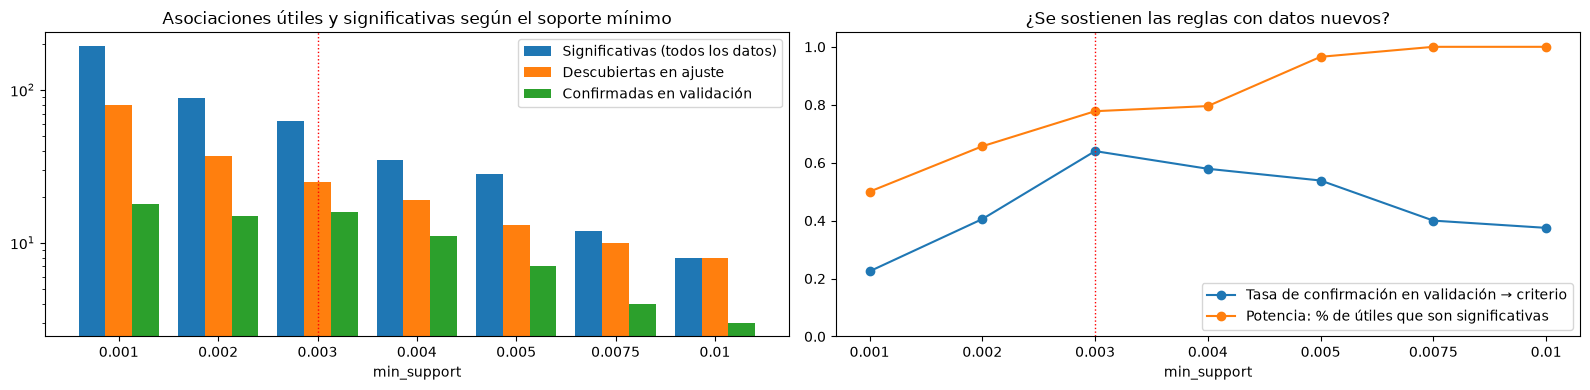

,min_baskets,n_rules,useful,significant,power,discovered_fit,confirmed_validation,confirmation_rate
min_support,,,,,,,,
0.0010,10,1544,386,193,0.50,80,18,0.22
0.0020,19,668,134,88,0.66,37,15,0.41
0.0030,29,392,81,63,0.78,25,16,0.64
0.0040,38,266,44,35,0.80,19,11,0.58
0.0050,48,194,29,28,0.97,13,7,0.54
0.0075,71,98,12,12,1.00,10,4,0.40
0.0100,95,74,8,8,1.00,8,3,0.38


In [32]:
SUPPORT_CANDIDATES = [0.001, 0.002, 0.003, 0.004, 0.005, 0.0075, 0.01]

support_selection = []
for min_support in SUPPORT_CANDIDATES:
    candidate_rules = add_significance(mine_rules(df, min_support, apriori), df)
    useful = collapse_directions(candidate_rules[candidate_rules['lift'] >= USEFUL_LIFT])
    fit_rules = add_significance(mine_rules(fit, min_support, apriori), fit)
    discovered = collapse_directions(fit_rules[(fit_rules['lift'] >= USEFUL_LIFT) & (fit_rules['q_positive'] < 0.05)])
    confirmed = holdout_q(discovered, validation) < 0.05
    support_selection.append({
        'min_support': min_support,
        'min_baskets': int(np.ceil(min_support * len(df))),
        'n_rules': len(candidate_rules),
        'useful': len(useful),
        'significant': (useful['q_positive'] < 0.05).sum(),
        'power': (useful['q_positive'] < 0.05).mean(),
        'discovered_fit': len(discovered),
        'confirmed_validation': confirmed.sum(),
        'confirmation_rate': confirmed.mean() if len(discovered) else np.nan,
    })
support_selection = pd.DataFrame(support_selection).set_index('min_support')

# idxmax keeps the first maximum, i.e. the lowest support in case of a tie
ANALYSIS_SUPPORT = support_selection['confirmation_rate'].idxmax()
print(f'Fit: {len(fit)} baskets | validation: {len(validation)} baskets (test is not used here)')
print(f"Selected min_support: {ANALYSIS_SUPPORT} (at least {support_selection.loc[ANALYSIS_SUPPORT, 'min_baskets']} baskets per rule)")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
positions = np.arange(len(support_selection))
ax[0].bar(positions - 0.27, support_selection['significant'], width=0.27, label='Significativas (todos los datos)')
ax[0].bar(positions, support_selection['discovered_fit'], width=0.27, label='Descubiertas en ajuste')
ax[0].bar(positions + 0.27, support_selection['confirmed_validation'], width=0.27, label='Confirmadas en validación')
ax[0].set_yscale('log')
ax[0].set_title('Asociaciones útiles y significativas según el soporte mínimo')

ax[1].plot(positions, support_selection['confirmation_rate'], marker='o', label='Tasa de confirmación en validación → criterio')
ax[1].plot(positions, support_selection['power'], marker='o', label='Potencia: % de útiles que son significativas')
ax[1].set_ylim(0, 1.05)
ax[1].set_title('¿Se sostienen las reglas con datos nuevos?')

selected_position = list(support_selection.index).index(ANALYSIS_SUPPORT)
for axis in ax:
    axis.axvline(selected_position, linestyle=':', color='red', linewidth=1)
    axis.set_xticks(positions, support_selection.index)
    axis.set_xlabel('min_support')
    axis.legend()
plt.tight_layout()
plt.show()

support_selection.round(2)

El ratio de confirmación alcanza su máximo en 0.003 (64 %, 16 de 25 reglas), por lo que usaremos este valor para generar nuestras reglas: cada regla se apoya en al menos 29 cestas. Con este valor tenemos un total de 63 asociaciones significativas (y el doble de reglas, una por cada dirección).

Por debajo de 0.003 la confirmación cae (22 % con 0.001, 41 % con 0.002): son reglas apoyadas en muy pocas cestas. Por encima no mejora (38–58 %) y solo se pierden asociaciones. Hay que tomar estas tasas con cautela: se calculan sobre 8–80 reglas y la validación solo tiene 1980 cestas, así que las diferencias pequeñas están dentro del ruido.

**Modelo.** Hemos comprobado que, para todas las combinaciones de soporte y confianza, los 3 modelos generan exactamente las mismas reglas, por lo que solo debemos escoger el modelo en función de su eficiencia con el soporte elegido. Combinamos tiempo y memoria: descartamos los algoritmos dominados (otro es igual o mejor en los dos criterios) y, entre los restantes, dividimos cada criterio por el mejor valor y los combinamos con la media geométrica (1 = el mejor en todo).

In [33]:
CRITERIA = ['mining_ms', 'memory_mb']

candidates = []
for name, algorithm in algorithms.items():
    mining_ms, found = measure_runtime(algorithm, ANALYSIS_SUPPORT)
    candidates.append({'algorithm': name, 'mining_ms': mining_ms,
                       'memory_mb': measure_memory(algorithm, ANALYSIS_SUPPORT), 'n_itemsets': len(found)})
candidates = pd.DataFrame(candidates).set_index('algorithm')


def is_dominated(name):
    others = candidates.drop(index=name)[CRITERIA]
    own = candidates.loc[name, CRITERIA]
    return ((others <= own).all(axis=1) & (others < own).any(axis=1)).any()


candidates['dominated'] = [is_dominated(name) for name in candidates.index]
candidates['time_ratio'] = candidates['mining_ms'] / candidates['mining_ms'].min()
candidates['memory_ratio'] = candidates['memory_mb'] / candidates['memory_mb'].min()
candidates['score'] = np.sqrt(candidates['time_ratio'] * candidates['memory_ratio'])
best_algorithm = candidates.loc[~candidates['dominated'], 'score'].idxmin()

print(f'Best algorithm at min_support = {ANALYSIS_SUPPORT}: {best_algorithm}')
candidates.sort_values('score').round(2)

Best algorithm at min_support = 0.003: ECLAT


,mining_ms,memory_mb,n_itemsets,dominated,time_ratio,memory_ratio,score
algorithm,,,,,,,
ECLAT,53.50,0.15,176,False,1.53,1.00,1.24
FP-Growth,84.44,0.70,176,True,2.41,4.54,3.31
Apriori,35.01,21.13,176,False,1.00,137.56,11.73


**Resultado:** con el soporte elegido (0.003), el que mejores resultados nos da es el algoritmo **ECLAT**, con el que funcionaremos desde este momento. FP-Growth queda dominado (más lento y con más memoria que ECLAT), y Apriori, aunque es el más rápido, usa más de 100 veces más memoria (21 MB frente a 0.15 MB). A esta escala las diferencias son de milisegundos y pocos MB, y al ser algoritmos exactos el análisis sería idéntico con cualquiera de los tres.

#### 4.2 Reglas, métricas y significación estadística
Además de las métricas típicas (soporte, confianza, lift, conviction y leverage), usamos:
- **Confianza inversa:** la confianza de la relación inversa (B → A) es útil al estudiar la original (A → B) como una propiedad de la misma: de todas las compras de B, cuántas van acompañadas de A. Por ejemplo, puede que comprar un croissant sea un muy buen indicador de la compra de café, pero que a la vez solo el 5 % de las compras de café vayan acompañadas de croissant. Esto es importante de estudiar si la intención es promocionarlos juntos (importante no confundir este estudio con el lift).
- **Cestas observadas frente a esperadas:** equivalente al lift, pero en números absolutos.
- **Kulczynski e Imbalance Ratio** (Wu, Chen y Han, 2010):
  - **Kulczynski:** media de las dos confianzas.
  - **Imbalance Ratio:** indica la simetría de las confianzas (para contrastar con Kulczynski): 0 significa que tienen la misma confianza; cerca de 1, que es una relación de inclusión.
- **Significación estadística:** usamos el **test de Fisher**. Al calcularlo sobre cientos de reglas, alguna puede pasar por azar (Webb, 2007), por lo que lo corregimos con:
  - **Benjamini-Hochberg** (controla la proporción de falsos descubrimientos): es el filtro. Una regla se acepta si q < 0.05.
  - **Bonferroni** (más estricta, controla la probabilidad de cometer un solo error): no descarta reglas. Marca cuáles de las aceptadas son especialmente sólidas.

Aclaración: a la hora de crear reglas, el filtro de confianza mínima lo dejamos a 0 para no perder asociaciones importantes. La confianza da preferencia a los productos comunes (Brin, Motwani y Silverstein, 1997): el café se encuentra en el 48 % de los tickets, por lo que prácticamente cualquier regla que tenga café como consecuente pasará este filtro, sea o no significativa. Mientras tanto, los productos poco frecuentes tendrán por naturaleza una confianza baja.

In [34]:
rules = add_significance(mine_rules(df, ANALYSIS_SUPPORT, algorithms[best_algorithm]), df)
rules['n_baskets'] = (rules['support'] * len(df)).round().astype(int)
rules['expected_baskets'] = (rules['antecedent support'] * rules['consequent support'] * len(df)).round().astype(int)
rules['reverse_confidence'] = rules['support'] / rules['consequent support']
# mlxtend already provides 'kulczynski'; the Imbalance Ratio completes the pair (Wu, Chen and Han, 2010)
rules['imbalance_ratio'] = ((rules['antecedent support'] - rules['consequent support']).abs()
                            / (rules['antecedent support'] + rules['consequent support'] - rules['support']))
rules['passes_bonferroni'] = rules['bonferroni_positive'] < 0.05

positive = rules[(rules['lift'] >= USEFUL_LIFT) & (rules['q_positive'] < 0.05)]
negative = rules[(rules['lift'] < 1) & (rules['q_negative'] < 0.05)]

print(f'Rules generated: {len(rules)}')
print(f"Rules with lift >= {USEFUL_LIFT}: {(rules['lift'] >= USEFUL_LIFT).sum()}")
print(f'  significant (Benjamini-Hochberg, q < 0.05): {len(positive)}')
print(f"  of which also pass Bonferroni: {positive['passes_bonferroni'].sum()}")
print(f"Rules with lift < 1: {(rules['lift'] < 1).sum()}")
print(f'  significant negative associations (q < 0.05): {len(negative)}')

Rules generated: 392
Rules with lift >= 1.2: 162
  significant (Benjamini-Hochberg, q < 0.05): 126
  of which also pass Bonferroni: 60
Rules with lift < 1: 144
  significant negative associations (q < 0.05): 94


Nótese que las relaciones están en ambas direcciones: A → B y B → A tienen el mismo lift y el mismo p-valor, por lo que realmente tenemos la mitad de asociaciones. De las 126 reglas positivas que han pasado el test de significatividad nos quedan 63 asociaciones (30 de ellas superan también Bonferroni). En las tablas se muestra cada asociación una sola vez, con el producto menos frecuente como antecedente. Las 94 reglas negativas significativas (47 asociaciones) se analizan en la sección 4.5.

#### 4.3 Asociaciones positivas

In [35]:
RULE_COLUMNS = ['antecedent', 'consequent', 'n_baskets', 'expected_baskets', 'support', 'confidence', 'reverse_confidence',
                'lift', 'kulczynski', 'imbalance_ratio', 'conviction', 'leverage', 'q_positive', 'passes_bonferroni']

positive_pairs = collapse_directions(positive)
print(f'Distinct associations (both directions collapsed): {len(positive_pairs)}')
print(f"  also passing Bonferroni: {positive_pairs['passes_bonferroni'].sum()}")
with pd.option_context('display.max_rows', 100):
    display(positive_pairs[RULE_COLUMNS].round(3))

Distinct associations (both directions collapsed): 63
  also passing Bonferroni: 30


,antecedent,consequent,n_baskets,expected_baskets,support,confidence,reverse_confidence,lift,kulczynski,imbalance_ratio,conviction,leverage,q_positive,passes_bonferroni
340,Coke,Sandwich,49,13,0.005,0.266,0.072,3.693,0.169,0.609,1.265,0.004,0.000,True
219,"Coffee, Cookies",Juice,35,10,0.004,0.131,0.096,3.387,0.113,0.164,1.106,0.003,0.000,True
218,"Coffee, Juice",Cookies,35,11,0.004,0.179,0.068,3.287,0.124,0.474,1.152,0.003,0.000,True
368,Mineral water,Sandwich,31,10,0.003,0.231,0.046,3.208,0.138,0.697,1.207,0.002,0.000,True
292,"Coffee, Soup",Sandwich,34,11,0.004,0.227,0.050,3.143,0.138,0.666,1.200,0.002,0.000,True
344,Juice,Cookies,58,20,0.006,0.159,0.113,2.910,0.136,0.182,1.124,0.004,0.000,True
296,Soup,"Coffee, Sandwich",34,13,0.004,0.104,0.094,2.717,0.099,0.055,1.074,0.002,0.000,True
378,Truffles,Sandwich,36,14,0.004,0.188,0.053,2.600,0.120,0.584,1.142,0.002,0.000,True
212,"Coffee, Hot chocolate",Cookies,35,15,0.004,0.125,0.068,2.289,0.096,0.309,1.080,0.002,0.000,True
213,"Coffee, Cookies",Hot chocolate,35,16,0.004,0.131,0.063,2.239,0.097,0.364,1.083,0.002,0.000,True


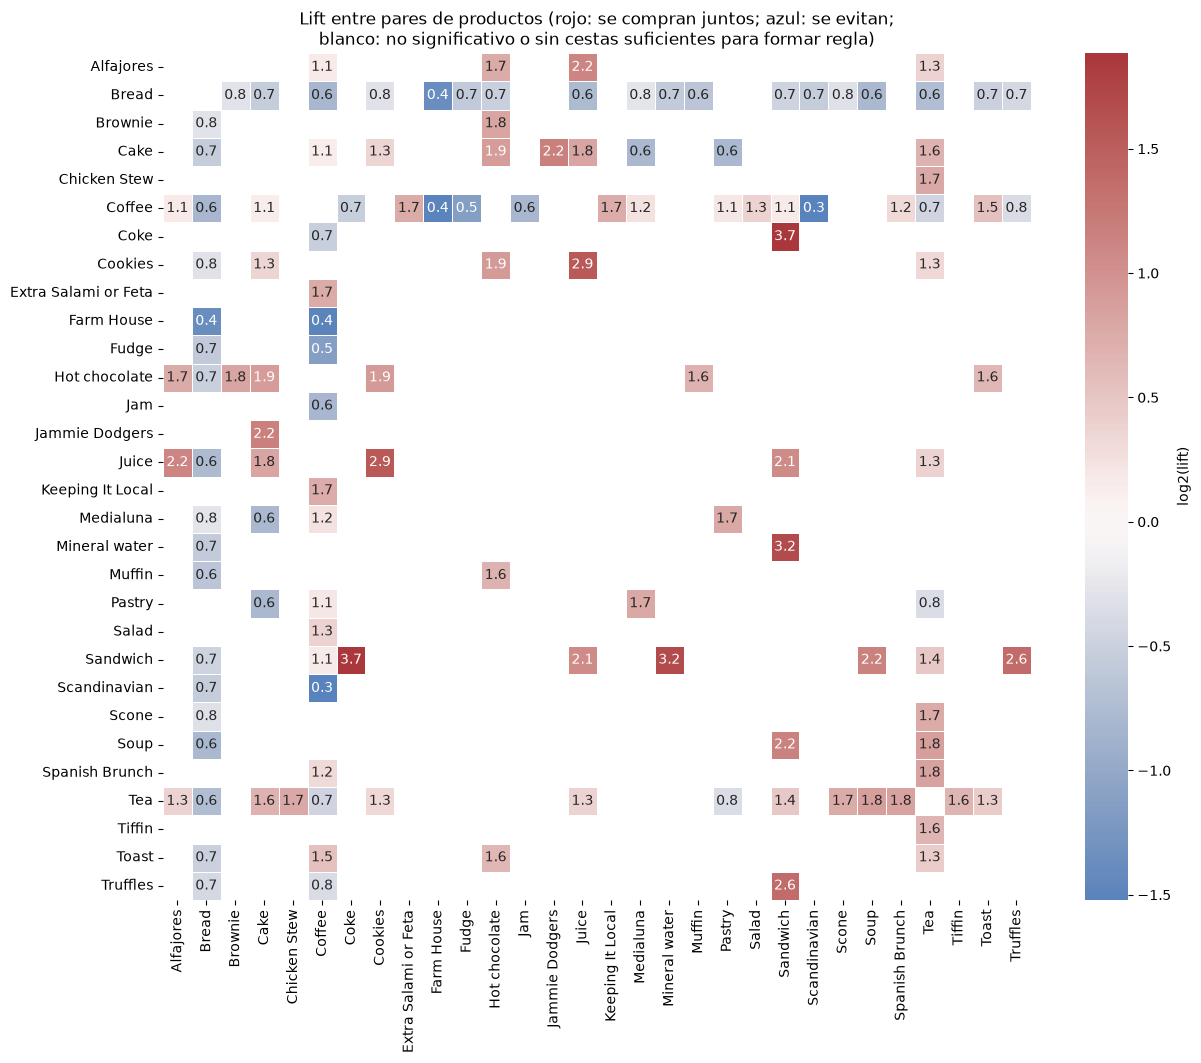

In [36]:
significant_pairs = rules[is_single_pair(rules) & ((rules['q_positive'] < 0.05) | (rules['q_negative'] < 0.05))]
pair_items = sorted(set(significant_pairs['antecedent']))
lift_matrix = significant_pairs.pivot(index='antecedent', columns='consequent', values='lift').reindex(index=pair_items, columns=pair_items)

plt.figure(figsize=(14, 11))
sns.heatmap(np.log2(lift_matrix), cmap='vlag', center=0, annot=lift_matrix.round(1), fmt='',
            cbar_kws={'label': 'log2(lift)'}, linewidths=0.5, linecolor='white')
plt.title('Lift entre pares de productos (rojo: se compran juntos; azul: se evitan;\n'
          'blanco: no significativo o sin cestas suficientes para formar regla)')
plt.xlabel('')
plt.ylabel('')
plt.show()

En este gráfico se puede ver el lift de las asociaciones entre pares: el rojo significa que se compran juntos (asociación positiva) y el azul que se evitan (asociación negativa). Las celdas en blanco no son significativas (relación esperable por azar) o no tienen cestas suficientes para formar regla.

Las 63 asociaciones cuadran con un comportamiento esperado: la creación de grupos de artículos de compra en función de necesidades o momentos concretos (Sarantopoulos et al., 2016), como el desayuno o el mediodía:
- **Bebida + dulce.** Hot chocolate + Cake (108 cestas frente a 58 esperadas, lift 1.88; con Coffee, 2.23), Juice + Cookies (2.91; con Coffee, 3.39), Cookies + Hot chocolate (1.89), Juice + Cake (1.76), Tea + Cake (225 frente a 141, lift 1.60) y Scone + Tea (1.69).
- **Comida de mediodía.** Sandwich + Coke (lift 3.69, la asociación más fuerte del dataset), Sandwich + Mineral water (3.21), Sandwich + Truffles (2.60), Sandwich + Soup (2.21; con Coffee, 3.14), Sandwich + Juice (2.09) y Sandwich + Tea (1.40). Tea se asocia también con los platos calientes: Soup (1.84), Chicken Stew (1.70) y Tiffin (1.58). Tiene una estructura de menú: comida + bebida.
- **Desayuno.** Toast → Coffee (224 cestas, confianza 0.70), Extra Salami or Feta → Coffee (0.82), Spanish Brunch → Coffee (0.60), Salad → Coffee (0.63), Medialuna + Pastry (1.72) y Pastry → Bread + Coffee (1.44).

En el heatmap destaca la fila de Bread, casi entera en azul: se compra menos de lo esperado con casi todo. La fila de Coffee separa dos grupos: en rojo, lo que se consume en la cafetería (Toast, Salad, Spanish Brunch, Extra Salami or Feta, Keeping It Local); en azul, los productos para llevar (Farm House, Scandinavian, Fudge, Jam) y las otras bebidas.

Hasta ahora hemos visto si dos productos se compran más de lo esperado, pero esto no nos habla de la naturaleza de la relación. Si las dos confianzas son altas, son productos que se suelen comprar a menudo juntos. Si por el contrario una de ellas es considerablemente más alta, estamos frente a un caso de inclusión. Un ejemplo es Toast y Coffee, una relación muy desequilibrada: cuando se compra una tostada se suele comprar café (el 70 % de las veces), pero cuando la gente compra café pocas veces compra tostada (el 5 % de las veces). A pesar de esto, la regla tiene un lift de 1.47.

Para este análisis usamos Kulczynski e Imbalance Ratio, y clasificamos cada asociación en cuatro tipos: **pareja cerrada** (las dos confianzas ≥ 0.5), **inclusión** (solo una ≥ 0.5), **débil equilibrada** (las dos < 0.5 e IR < 0.5) y **débil desequilibrada** (las dos < 0.5 e IR ≥ 0.5).

relation_type
débil equilibrada       35
débil desequilibrada    19
inclusión                9


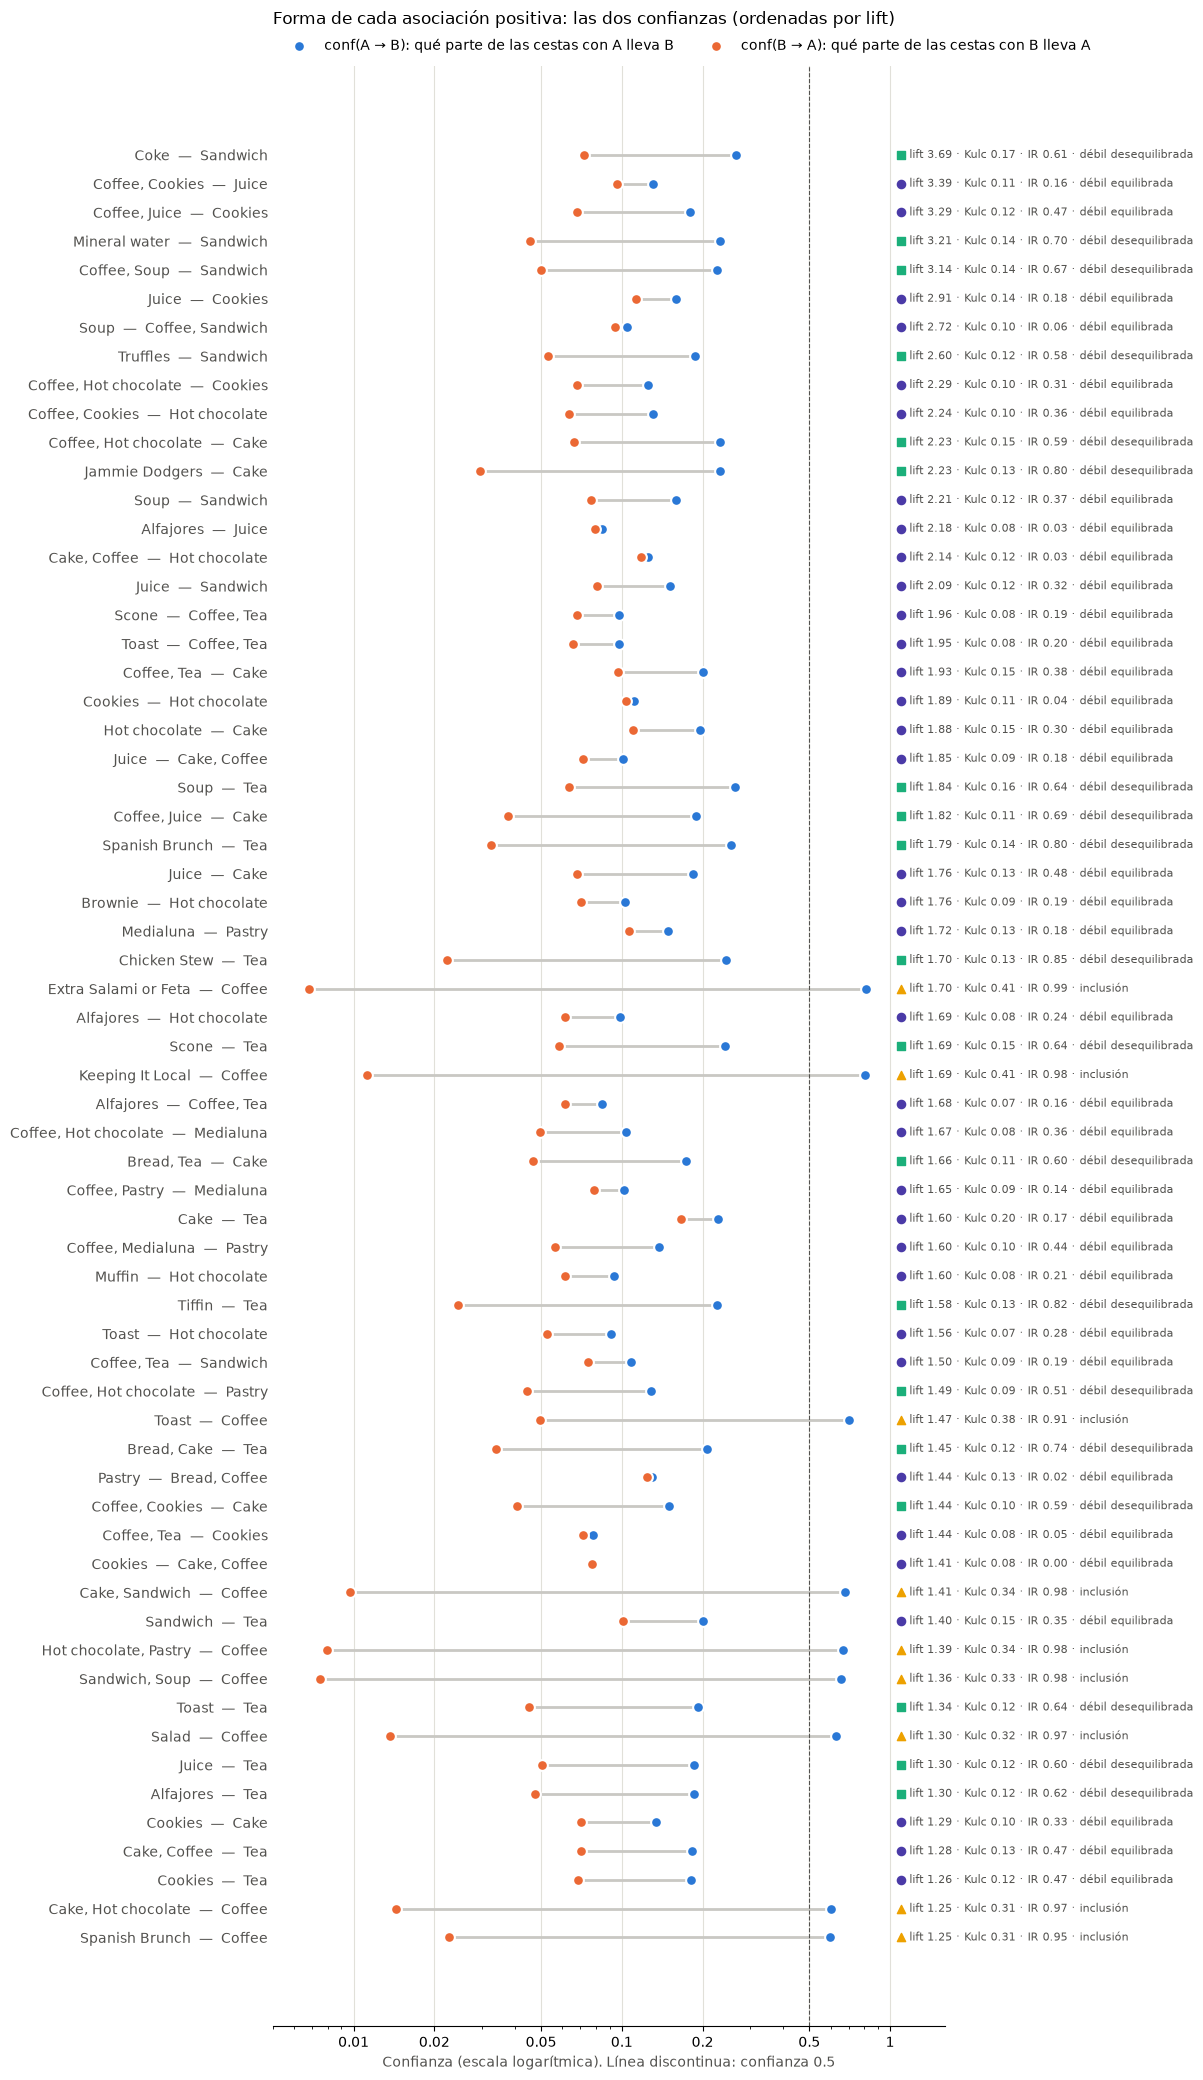

,antecedent,consequent,n_baskets,lift,confidence,reverse_confidence,kulczynski,imbalance_ratio,passes_bonferroni,relation_type
231,Extra Salami or Feta,Coffee,31,1.699,0.816,0.007,0.411,0.990,True,inclusion
261,Keeping It Local,Coffee,51,1.686,0.810,0.011,0.410,0.983,True,inclusion
335,Toast,Coffee,224,1.467,0.704,0.049,0.377,0.911,True,inclusion
172,"Cake, Sandwich",Coffee,44,1.410,0.677,0.010,0.343,0.981,False,inclusion
250,"Hot chocolate, Pastry",Coffee,36,1.388,0.667,0.008,0.337,0.984,False,inclusion
294,"Sandwich, Soup",Coffee,34,1.362,0.654,0.008,0.331,0.985,False,inclusion
289,Salad,Coffee,62,1.304,0.626,0.014,0.320,0.970,False,inclusion
160,"Cake, Hot chocolate",Coffee,65,1.253,0.602,0.014,0.308,0.967,False,inclusion
318,Spanish Brunch,Coffee,103,1.247,0.599,0.023,0.311,0.948,False,inclusion
219,"Coffee, Cookies",Juice,35,3.387,0.131,0.096,0.113,0.164,True,weak balanced


In [37]:
HIGH_CONFIDENCE = 0.5  # the product goes with the other in more than half of its baskets
BALANCED_IR = 0.5      # below this, neither product sells more than ~3 times the other
RELATION_LABELS = {'tight pair': 'pareja cerrada', 'inclusion': 'inclusión',
                   'weak balanced': 'débil equilibrada', 'weak unbalanced': 'débil desequilibrada'}
# Color + marker per relation type (validated as a categorical set; the marker is the secondary encoding)
RELATION_STYLE = {'weak balanced': ('#4a3aa7', 'o'), 'weak unbalanced': ('#1baf7a', 's'),
                  'inclusion': ('#eda100', '^'), 'tight pair': ('#e87ba4', 'D')}
FORWARD_COLOR, REVERSE_COLOR, LINK_COLOR, TEXT_COLOR = '#2a78d6', '#eb6834', '#c9c8c3', '#52514e'
MUTED_COLOR, GRID_COLOR = '#898781', '#e1e0d9'

relation_shape = positive_pairs[['antecedent', 'consequent', 'n_baskets', 'lift', 'confidence', 'reverse_confidence',
                                 'kulczynski', 'imbalance_ratio', 'passes_bonferroni']].copy()
# positive_pairs keeps the direction with the higher confidence, so 'confidence' is the larger of the two
relation_shape['relation_type'] = np.select(
    [relation_shape['reverse_confidence'] >= HIGH_CONFIDENCE,
     relation_shape['confidence'] >= HIGH_CONFIDENCE,
     relation_shape['imbalance_ratio'] < BALANCED_IR],
    ['tight pair', 'inclusion', 'weak balanced'],
    default='weak unbalanced')
print(relation_shape['relation_type'].map(RELATION_LABELS).value_counts().to_string())

plot_data = relation_shape.sort_values('lift').reset_index(drop=True)
rows = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(12, 0.3 * len(plot_data) + 2))
ax.hlines(rows, plot_data['reverse_confidence'], plot_data['confidence'], color=LINK_COLOR, linewidth=2, zorder=1)
ax.scatter(plot_data['confidence'], rows, s=60, color=FORWARD_COLOR, edgecolor='white', linewidth=1.5, zorder=2,
           label='conf(A → B): qué parte de las cestas con A lleva B')
ax.scatter(plot_data['reverse_confidence'], rows, s=60, color=REVERSE_COLOR, edgecolor='white', linewidth=1.5, zorder=2,
           label='conf(B → A): qué parte de las cestas con B lleva A')
ax.axvline(HIGH_CONFIDENCE, linestyle='--', color=TEXT_COLOR, linewidth=0.8)

ax.set_xscale('log')
ax.set_xlim(0.005, 1.6)
ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1], ['0.01', '0.02', '0.05', '0.1', '0.2', '0.5', '1'])
ax.set_yticks(rows, plot_data['antecedent'] + '  —  ' + plot_data['consequent'], color=TEXT_COLOR)
for row, item in plot_data.iterrows():
    color, marker = RELATION_STYLE[item['relation_type']]
    ax.scatter(1.1, row, s=35, color=color, marker=marker, clip_on=False, zorder=3)
    ax.text(1.18, row, f"lift {item['lift']:.2f} · Kulc {item['kulczynski']:.2f} · IR {item['imbalance_ratio']:.2f} · "
                       f"{RELATION_LABELS[item['relation_type']]}",
            va='center', fontsize=8, color=TEXT_COLOR)
ax.grid(axis='x', color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_xlabel('Confianza (escala logarítmica). Línea discontinua: confianza 0.5', color=TEXT_COLOR)
ax.set_title('Forma de cada asociación positiva: las dos confianzas (ordenadas por lift)', loc='left', pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

with pd.option_context('display.max_rows', 100):
    display(relation_shape.sort_values(['relation_type', 'lift'], ascending=[True, False]).round(3))

Cada fila es una asociación: el punto azul es la confianza desde el producto menos frecuente (A → B) y el naranja la confianza desde el más frecuente (B → A).

El valor de Kulczynski no supera 0.41 en ninguna regla, lo que significa que no tenemos ninguna compra que vaya "casi siempre junta" (no hay parejas cerradas). Por otro lado, tenemos 9 asociaciones de inclusión, todas con el café como consecuente: ya dijimos que era normal que el café saliera como consecuente en muchas reglas por su alta frecuencia. El resto son débiles: 35 equilibradas y 19 desequilibradas.

Las reglas con un ratio de equilibrio cercano a 0 son buenas para tareas como decidir cómo ordenar los productos en un supermercado o crear packs; si no, se puede caer en la trampa vista con el café. Mientras tanto, las reglas de inclusión como la de la tostada son más útiles para tareas como recomendaciones o promociones.

Un buen gráfico para analizar las reglas de cara a la toma de decisiones es el siguiente. Tenemos 2 ejes con los valores de IR y Kulczynski. En el gráfico de la izquierda se pueden ver las posibles combinaciones de estos dos valores y la zona de cada tipo, importante a la hora de tomar decisiones según la tarea a resolver; la zona en blanco es imposible matemáticamente (exigiría una confianza mayor que 1). En el gráfico de la derecha (versión aumentada del de la izquierda) vemos la distribución de nuestras asociaciones; el tamaño de cada punto representa la cantidad de cestas que contienen los dos ítems.

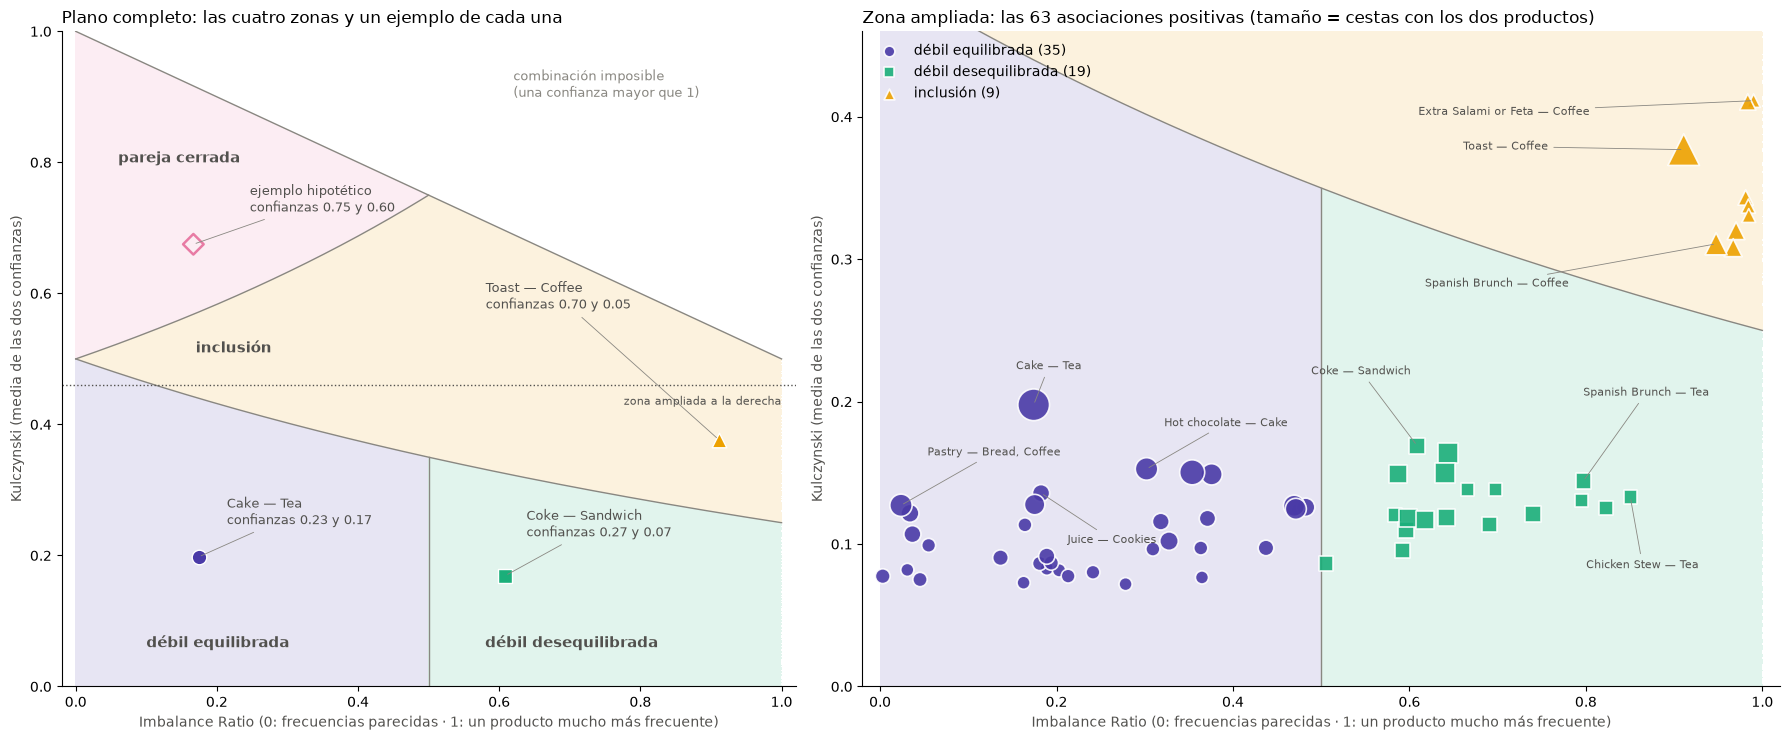

kulczynski              imbalance_ratio               \
                            min median   max             min median   max   
relation_type                                                               
inclusión                  0.31   0.34  0.41            0.91   0.98  0.99   
débil equilibrada          0.07   0.10  0.20            0.00   0.20  0.48   
débil desequilibrada       0.09   0.13  0.17            0.51   0.64  0.85   

                      lift              confidence               \
                       min median   max        min median   max   
relation_type                                                     
inclusión             1.25   1.39  1.70       0.60   0.67  0.82   
débil equilibrada     1.26   1.76  3.39       0.08   0.13  0.23   
débil desequilibrada  1.30   1.70  3.69       0.13   0.23  0.27   

                     reverse_confidence               
                                    min median   max  
relation_type                                         
inclusión                          0.01   0.01  0.05  
débil equilibrada                  0.05   0.07  0.17  
débil desequilibrada               0.02   0.05  0.07

In [38]:
from matplotlib.colors import ListedColormap

RELATION_ORDER = ['weak balanced', 'weak unbalanced', 'inclusion', 'tight pair']
ZOOM_KULCZYNSKI = 0.46
EXAMPLE_PAIRS = { 
    ('Cake', 'Tea'): (0.04, 0.05), ('Coke', 'Sandwich'): (0.03, 0.06), ('Toast', 'Coffee'): (-0.33, 0.2),
}
HYPOTHETICAL_TIGHT_PAIR = (0.75, 0.60)  
MAP_LABELS = { 
    ('Cake', 'Tea'): (-0.02, 0.025), ('Hot chocolate', 'Cake'): (0.02, 0.03), ('Juice', 'Cookies'): (0.03, -0.035),
    ('Pastry', 'Bread, Coffee'): (0.03, 0.035), ('Coke', 'Sandwich'): (-0.12, 0.05), ('Spanish Brunch', 'Tea'): (0.0, 0.06),
    ('Chicken Stew', 'Tea'): (-0.05, -0.05), ('Toast', 'Coffee'): (-0.25, 0.0),
    ('Extra Salami or Feta', 'Coffee'): (-0.38, -0.01), ('Spanish Brunch', 'Coffee'): (-0.33, -0.03),
}


def shape_coordinates(high_confidence, low_confidence):
  
    kulczynski = (high_confidence + low_confidence) / 2
    imbalance = (high_confidence - low_confidence) / (high_confidence + low_confidence - high_confidence * low_confidence)
    return imbalance, kulczynski


def confidences_from_shape(imbalance, kulczynski):
   
    total = 2 * kulczynski
    discriminant = 1 - imbalance ** 2 * (total - total ** 2 / 4)
    with np.errstate(divide='ignore', invalid='ignore'):
        gap = np.where(imbalance > 0, (1 - np.sqrt(discriminant)) / (imbalance / 2), 0.0)
    high, low = (total + gap) / 2, (total - gap) / 2
    feasible = (discriminant >= 0) & (high <= 1) & (low >= 0)
    return np.where(feasible, high, np.nan), np.where(feasible, low, np.nan)


def pair_label(row):
    return f"{row['antecedent']} — {row['consequent']}"


def draw_zones(ax):
    grid = np.linspace(0, 1, 801)
    imbalance_grid, kulczynski_grid = np.meshgrid(grid, grid)
    high, low = confidences_from_shape(imbalance_grid, kulczynski_grid)
    zone = np.select([low >= HIGH_CONFIDENCE, high >= HIGH_CONFIDENCE, imbalance_grid < BALANCED_IR], [3, 2, 0], default=1)
    zone = np.where(np.isnan(high), np.nan, zone)
    zone_cmap = ListedColormap([RELATION_STYLE[kind][0] for kind in RELATION_ORDER])
    ax.pcolormesh(grid, grid, zone, cmap=zone_cmap, vmin=-0.5, vmax=3.5, alpha=0.13, shading='auto', zorder=0)

    steps = np.linspace(0, 1, 200)
    for high_conf, low_conf in [(np.full_like(steps, HIGH_CONFIDENCE), steps * HIGH_CONFIDENCE),
                                (HIGH_CONFIDENCE + steps * (1 - HIGH_CONFIDENCE), np.full_like(steps, HIGH_CONFIDENCE)),
                                (np.ones_like(steps), steps)]:
        ax.plot(*shape_coordinates(high_conf, low_conf), color=MUTED_COLOR, linewidth=1, zorder=1)

    low_at_split = HIGH_CONFIDENCE * (1 - BALANCED_IR) / (1 + BALANCED_IR * HIGH_CONFIDENCE)
    ax.plot([BALANCED_IR, BALANCED_IR], [0, (HIGH_CONFIDENCE + low_at_split) / 2], color=MUTED_COLOR, linewidth=1, zorder=1)


def style_map_axis(ax, top):
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(0, top)
    ax.set_xlabel('Imbalance Ratio (0: frecuencias parecidas · 1: un producto mucho más frecuente)', color=TEXT_COLOR)
    ax.set_ylabel('Kulczynski (media de las dos confianzas)', color=TEXT_COLOR)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


fig, (full_ax, zoom_ax) = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={'width_ratios': [1, 1.25]})


draw_zones(full_ax)
style_map_axis(full_ax, 1.0)
for kind, (x, y) in {'tight pair': (0.06, 0.80), 'inclusion': (0.17, 0.51), 'weak balanced': (0.1, 0.06),
                     'weak unbalanced': (0.58, 0.06)}.items():
    full_ax.text(x, y, RELATION_LABELS[kind], fontsize=11, color=TEXT_COLOR, weight='bold')
full_ax.text(0.62, 0.9, 'combinación imposible\n(una confianza mayor que 1)', fontsize=9, color=MUTED_COLOR)
for (antecedent, consequent), (dx, dy) in EXAMPLE_PAIRS.items():
    row = relation_shape[(relation_shape['antecedent'] == antecedent) & (relation_shape['consequent'] == consequent)].iloc[0]
    color, marker = RELATION_STYLE[row['relation_type']]
    full_ax.scatter(row['imbalance_ratio'], row['kulczynski'], s=110, c=color, marker=marker, edgecolor='white', zorder=3)
    full_ax.annotate(f"{pair_label(row)}\nconfianzas {row['confidence']:.2f} y {row['reverse_confidence']:.2f}",
                     (row['imbalance_ratio'], row['kulczynski']),
                     xytext=(row['imbalance_ratio'] + dx, row['kulczynski'] + dy), fontsize=9, color=TEXT_COLOR,
                     arrowprops={'arrowstyle': '-', 'color': MUTED_COLOR, 'linewidth': 0.6})
tight_ir, tight_kulczynski = shape_coordinates(*HYPOTHETICAL_TIGHT_PAIR)
full_ax.scatter(tight_ir, tight_kulczynski, s=110, facecolor='none', edgecolor=RELATION_STYLE['tight pair'][0],
                marker='D', linewidth=1.8, zorder=3)
full_ax.annotate(f'ejemplo hipotético\nconfianzas {HYPOTHETICAL_TIGHT_PAIR[0]:.2f} y {HYPOTHETICAL_TIGHT_PAIR[1]:.2f}',
                 (tight_ir, tight_kulczynski), xytext=(tight_ir + 0.08, tight_kulczynski + 0.05), fontsize=9,
                 color=TEXT_COLOR, arrowprops={'arrowstyle': '-', 'color': MUTED_COLOR, 'linewidth': 0.6})
full_ax.axhline(ZOOM_KULCZYNSKI, color=TEXT_COLOR, linestyle=':', linewidth=1)
full_ax.text(1.0, ZOOM_KULCZYNSKI - 0.03, 'zona ampliada a la derecha', ha='right', fontsize=8, color=TEXT_COLOR)
full_ax.set_title('Plano completo: las cuatro zonas y un ejemplo de cada una', loc='left')

# Right panel: zoom on the 63 positive associations
draw_zones(zoom_ax)
style_map_axis(zoom_ax, ZOOM_KULCZYNSKI)
for kind in RELATION_ORDER:
    group = relation_shape[relation_shape['relation_type'] == kind]
    if group.empty:
        continue
    color, marker = RELATION_STYLE[kind]
    zoom_ax.scatter(group['imbalance_ratio'], group['kulczynski'], s=group['n_baskets'] * 2.2 + 25, c=color, marker=marker,
                    edgecolor='white', linewidth=1.2, alpha=0.9, label=f'{RELATION_LABELS[kind]} ({len(group)})', zorder=3)
for (antecedent, consequent), (dx, dy) in MAP_LABELS.items():
    row = relation_shape[(relation_shape['antecedent'] == antecedent) & (relation_shape['consequent'] == consequent)].iloc[0]
    zoom_ax.annotate(pair_label(row), (row['imbalance_ratio'], row['kulczynski']),
                     xytext=(row['imbalance_ratio'] + dx, row['kulczynski'] + dy), fontsize=8, color=TEXT_COLOR,
                     arrowprops={'arrowstyle': '-', 'color': MUTED_COLOR, 'linewidth': 0.6})
legend = zoom_ax.legend(loc='upper left', frameon=False)
for handle in legend.legend_handles:
    handle.set_sizes([60])
zoom_ax.set_title('Zona ampliada: las 63 asociaciones positivas (tamaño = cestas con los dos productos)', loc='left')
plt.tight_layout()
plt.show()

relation_shape.groupby('relation_type')[['kulczynski', 'imbalance_ratio', 'lift', 'confidence', 'reverse_confidence']] \
    .agg(['min', 'median', 'max']).rename(index=RELATION_LABELS).round(2)

**Lift frente a Kulczynski.** El lift dice si dos productos se compran juntos más de lo esperado, y Kulczynski cuánto coinciden en términos absolutos. Juntamos las 63 asociaciones positivas y las 47 negativas.

Spearman correlation lift vs Kulczynski (positive associations): -0.09
          count   mean    std    min    25%    50%    75%    max
sign                                                            
negative   47.0  0.127  0.043  0.048  0.102  0.117  0.147  0.232
positive   63.0  0.148  0.088  0.072  0.096  0.121  0.149  0.411


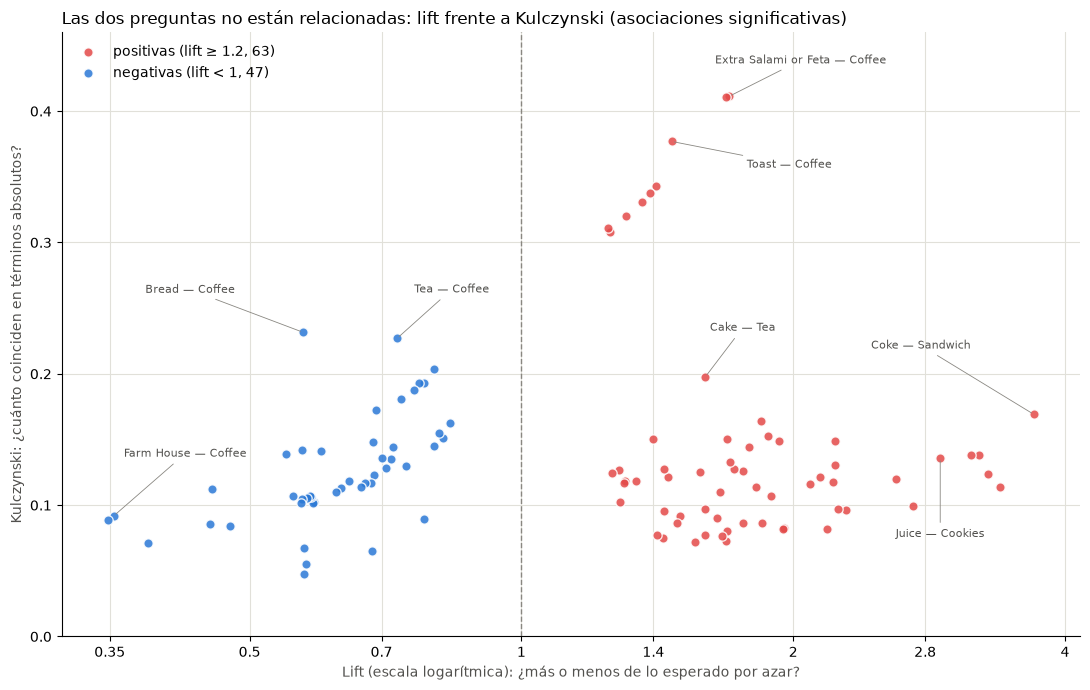

In [39]:
POSITIVE_COLOR, NEGATIVE_COLOR = '#e34948', '#2a78d6'  # same polarity convention as the lift heatmap
TWO_QUESTIONS_LABELS = {  
    ('Bread', 'Coffee'): (0.75, 0.03), ('Tea', 'Coffee'): (1.15, 0.035), ('Farm House', 'Coffee'): (1.2, 0.045),
    ('Coke', 'Sandwich'): (0.75, 0.05), ('Juice', 'Cookies'): (1.0, -0.06), ('Cake', 'Tea'): (1.1, 0.035),
    ('Toast', 'Coffee'): (1.35, -0.02), ('Extra Salami or Feta', 'Coffee'): (1.2, 0.025),
}

negative_shape = collapse_directions(negative)
both_signs = pd.concat([positive_pairs.assign(sign='positive'), negative_shape.assign(sign='negative')])
rho_positive = spearmanr(positive_pairs['lift'], positive_pairs['kulczynski']).statistic
print(f'Spearman correlation lift vs Kulczynski (positive associations): {rho_positive:.2f}')
print(both_signs.groupby('sign')['kulczynski'].describe().round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 7))
for sign, color, label in [('positive', POSITIVE_COLOR, f'positivas (lift ≥ {USEFUL_LIFT}, {len(positive_pairs)})'),
                           ('negative', NEGATIVE_COLOR, f'negativas (lift < 1, {len(negative_shape)})')]:
    group = both_signs[both_signs['sign'] == sign]
    ax.scatter(group['lift'], group['kulczynski'], s=45, c=color, edgecolor='white', linewidth=1, alpha=0.85,
               label=label, zorder=3)
ax.axvline(1, linestyle='--', color=MUTED_COLOR, linewidth=1)
for (antecedent, consequent), (x_factor, dy) in TWO_QUESTIONS_LABELS.items():
    row = both_signs[(both_signs['antecedent'] == antecedent) & (both_signs['consequent'] == consequent)].iloc[0]
    ax.annotate(pair_label(row), (row['lift'], row['kulczynski']), xytext=(row['lift'] * x_factor, row['kulczynski'] + dy),
                fontsize=8, color=TEXT_COLOR, ha='center', arrowprops={'arrowstyle': '-', 'color': MUTED_COLOR, 'linewidth': 0.6})
ax.set_xscale('log', base=2)
ax.set_xticks([0.35, 0.5, 0.7, 1, 1.4, 2, 2.8, 4], ['0.35', '0.5', '0.7', '1', '1.4', '2', '2.8', '4'])
ax.set_ylim(0, 0.46)
ax.set_xlabel('Lift (escala logarítmica): ¿más o menos de lo esperado por azar?', color=TEXT_COLOR)
ax.set_ylabel('Kulczynski: ¿cuánto coinciden en términos absolutos?', color=TEXT_COLOR)
ax.set_title('Las dos preguntas no están relacionadas: lift frente a Kulczynski (asociaciones significativas)', loc='left')
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

Max |Kulczynski - lift x mean popularity|: 5.6e-17


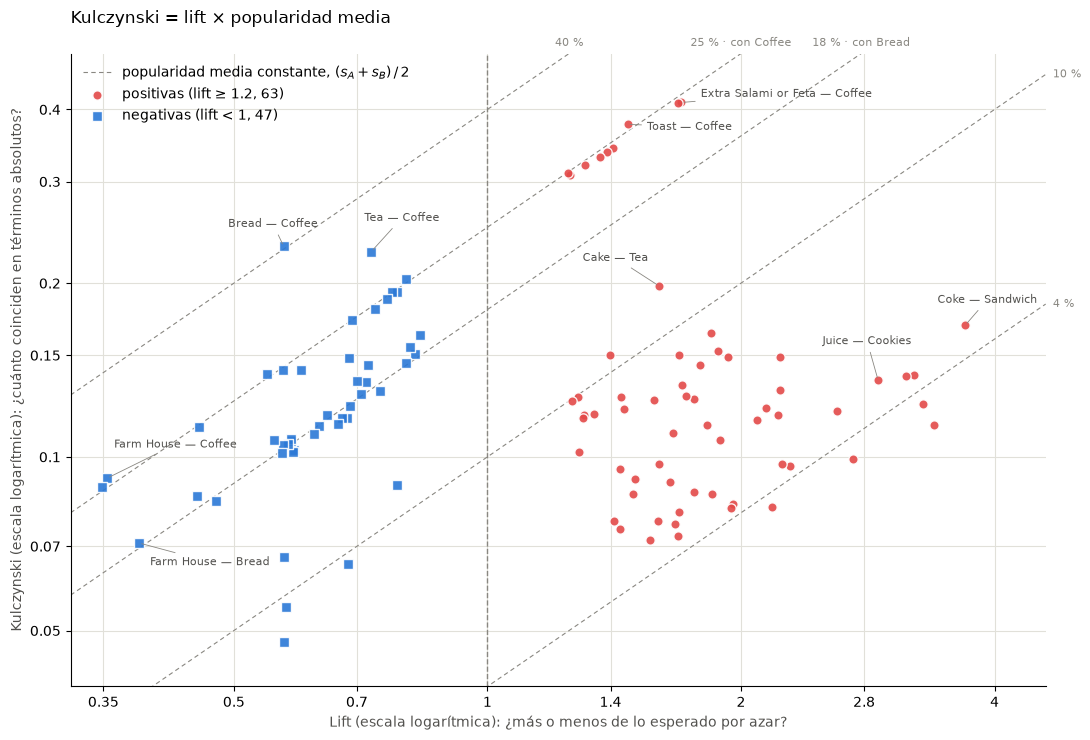

In [40]:
# Kulczynski = (conf(A→B) + conf(B→A)) / 2 = lift · (s_A + s_B) / 2: lift times the mean popularity of the two sides
ISO_POPULARITY = {0.04: '4 %', 0.1: '10 %', 0.18: '18 % · con Bread', 0.25: '25 % · con Coffee', 0.4: '40 %'}
LIFT_LIMITS, KULCZYNSKI_LIMITS = (0.32, 4.6), (0.04, 0.5)
DECOMPOSITION_LABELS = {  # text offset in points
    ('Bread', 'Coffee'): (-40, 14), ('Tea', 'Coffee'): (-5, 22), ('Farm House', 'Coffee'): (5, 22),
    ('Farm House', 'Bread'): (8, -16), ('Coke', 'Sandwich'): (-20, 16), ('Juice', 'Cookies'): (-40, 26),
    ('Cake', 'Tea'): (-55, 18), ('Toast', 'Coffee'): (14, -4), ('Extra Salami or Feta', 'Coffee'): (14, 4),
}

decomposition = both_signs.assign(
    mean_popularity=(both_signs['antecedent support'] + both_signs['consequent support']) / 2)
identity_error = (decomposition['kulczynski'] - decomposition['lift'] * decomposition['mean_popularity']).abs().max()
print(f'Max |Kulczynski - lift x mean popularity|: {identity_error:.1e}')

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlim(*LIFT_LIMITS)
ax.set_ylim(*KULCZYNSKI_LIMITS)

# Iso-popularity lines, labelled where they leave the plot (top edge or right edge)
lift_grid = np.geomspace(*LIFT_LIMITS, 200)
for popularity, label in ISO_POPULARITY.items():
    ax.plot(lift_grid, lift_grid * popularity, color=MUTED_COLOR, linewidth=0.8, linestyle=(0, (4, 3)), zorder=1)
    if LIFT_LIMITS[1] * popularity > KULCZYNSKI_LIMITS[1]:
        ax.text(KULCZYNSKI_LIMITS[1] / popularity, KULCZYNSKI_LIMITS[1] * 1.02, label, ha='center', va='bottom',
                fontsize=8, color=MUTED_COLOR)
    else:
        ax.text(LIFT_LIMITS[1] * 1.02, LIFT_LIMITS[1] * popularity, label, ha='left', va='center',
                fontsize=8, color=MUTED_COLOR)
ax.plot([], [], color=MUTED_COLOR, linewidth=0.8, linestyle=(0, (4, 3)),
        label=r'popularidad media constante, $(s_A + s_B)\,/\,2$')

ax.axvline(1, linestyle='--', color=MUTED_COLOR, linewidth=1, zorder=1)
for sign, color, marker, label in [
        ('positive', POSITIVE_COLOR, 'o', f'positivas (lift ≥ {USEFUL_LIFT}, {len(positive_pairs)})'),
        ('negative', NEGATIVE_COLOR, 's', f'negativas (lift < 1, {len(negative_shape)})')]:
    group = decomposition[decomposition['sign'] == sign]
    ax.scatter(group['lift'], group['kulczynski'], s=45, c=color, marker=marker, edgecolor='white', linewidth=1,
               alpha=0.9, label=label, zorder=3)
for (antecedent, consequent), offset in DECOMPOSITION_LABELS.items():
    row = decomposition[(decomposition['antecedent'] == antecedent) & (decomposition['consequent'] == consequent)].iloc[0]
    ax.annotate(pair_label(row), (row['lift'], row['kulczynski']), xytext=offset, textcoords='offset points',
                fontsize=8, color=TEXT_COLOR, arrowprops={'arrowstyle': '-', 'color': MUTED_COLOR, 'linewidth': 0.6})

ax.set_xticks([0.35, 0.5, 0.7, 1, 1.4, 2, 2.8, 4], ['0.35', '0.5', '0.7', '1', '1.4', '2', '2.8', '4'])
ax.set_yticks([0.05, 0.07, 0.1, 0.15, 0.2, 0.3, 0.4], ['0.05', '0.07', '0.1', '0.15', '0.2', '0.3', '0.4'])
ax.minorticks_off()
ax.set_xlabel('Lift (escala logarítmica): ¿más o menos de lo esperado por azar?', color=TEXT_COLOR)
ax.set_ylabel('Kulczynski (escala logarítmica): ¿cuánto coinciden en términos absolutos?', color=TEXT_COLOR)
ax.set_title('Kulczynski = lift × popularidad media',
             loc='left', pad=22)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

 Las dos métricas no responden a lo mismo: Bread–Coffee y Tea–Coffee coinciden mucho en términos absolutos (Kulczynski 0.23) y, sin embargo, se compran juntos menos de lo esperado, mientras que Coke–Sandwich tiene el lift más alto (3.69) con un Kulczynski de solo 0.17. La relación entre ambas es exacta: Kulczynski = lift × popularidad media de los dos productos (segundo gráfico, en escala logarítmica). A igual lift, una asociación está más arriba solo porque sus productos se venden más. Por eso las inclusiones y las negativas con café caen sobre la misma línea, y las negativas, que solo llegan al soporte mínimo si sus productos se venden mucho, tienen siempre un Kulczynski alto.

#### 4.4 Complementariedad frente a coincidencia
Hemos analizado parte de la naturaleza de las relaciones, en este caso su direccionalidad, lo que nos dice cómo podemos tomar las decisiones. Otro elemento de la naturaleza de estas reglas es la razón por la que los productos aparecen juntos. Se distinguen dos casos (Manchanda, Ansari y Gupta, 1999):
- **Complementariedad:** comprar uno aumenta la probabilidad de comprar el otro porque se consumen juntos, se complementan.
- **Coincidencia:** ambos dependen de un factor común, por ejemplo el momento de compra, aunque no tengan relación entre sí.

Esta distinción es de gran importancia. La complementariedad se puede aprovechar para acciones comerciales, mientras que la coincidencia no añade información extra. Si dos artículos tienden a venderse mucho en la misma franja horaria, su lift será mayor que 1 aunque sean independientes dentro de cada franja: si la tienda ya sabe el momento del día, saber que se ha comprado un producto no aumenta la probabilidad de que se compre el segundo. Es un efecto relacionado con la paradoja de Simpson (Simpson, 1951).

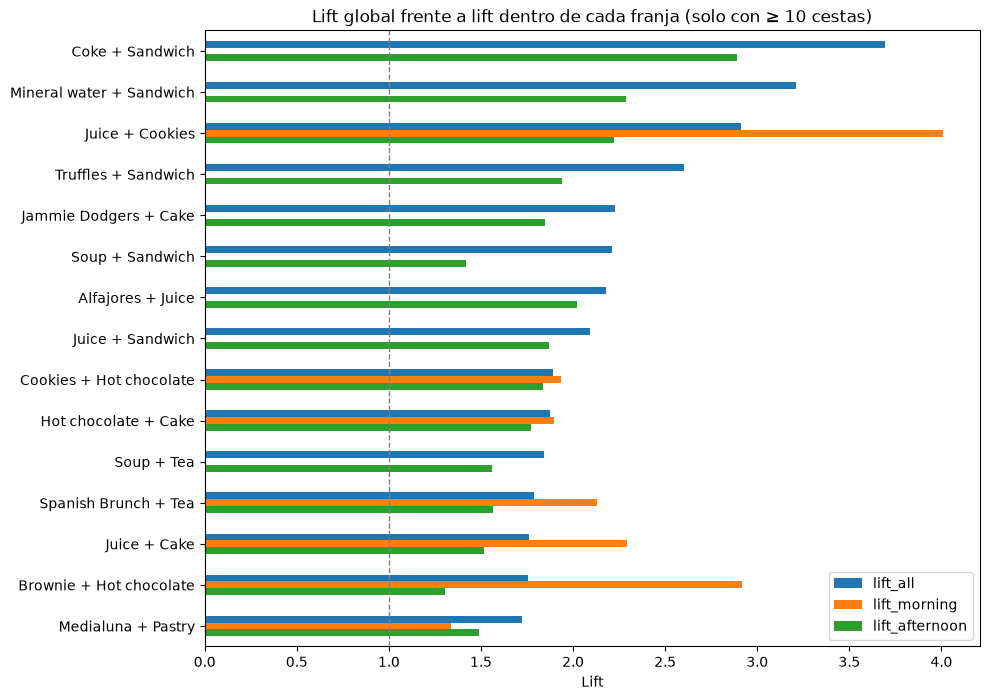

,antecedent,consequent,lift_all,lift_morning,n_morning,lift_afternoon,n_afternoon
340,Coke,Sandwich,3.69,NaN,2,2.89,47
368,Mineral water,Sandwich,3.21,NaN,2,2.29,29
344,Juice,Cookies,2.91,4.01,25,2.22,29
378,Truffles,Sandwich,2.60,NaN,2,1.94,34
187,Jammie Dodgers,Cake,2.23,NaN,7,1.85,21
374,Soup,Sandwich,2.21,NaN,1,1.42,51
21,Alfajores,Juice,2.18,NaN,8,2.02,20
360,Juice,Sandwich,2.09,NaN,7,1.87,48
343,Cookies,Hot chocolate,1.89,1.94,20,1.84,34
184,Hot chocolate,Cake,1.88,1.89,26,1.77,76


In [41]:
PERIODS = ['morning', 'afternoon']
MIN_CONTEXT_BASKETS = 10
N_CONTEXT_PAIRS = 15
period_of_basket = transaction['period_day'].to_numpy()

top_pairs = collapse_directions(positive[is_single_pair(positive)]).head(N_CONTEXT_PAIRS)
context = top_pairs[['antecedent', 'consequent', 'lift']].rename(columns={'lift': 'lift_all'})
for period in PERIODS:
    subset = df[period_of_basket == period]
    n_baskets = [int((basket_mask(subset, a) & basket_mask(subset, c)).sum())
                 for a, c in zip(top_pairs['antecedents'], top_pairs['consequents'])]
    lifts = [pair_lift(subset, a, c) for a, c in zip(top_pairs['antecedents'], top_pairs['consequents'])]
    context[f'lift_{period}'] = [lift if n >= MIN_CONTEXT_BASKETS else np.nan for lift, n in zip(lifts, n_baskets)]
    context[f'n_{period}'] = n_baskets

labels = context['antecedent'] + ' + ' + context['consequent']
context[['lift_all', 'lift_morning', 'lift_afternoon']].set_axis(labels).plot(kind='barh', figsize=(10, 8))
plt.axvline(1, linestyle='--', color='gray', linewidth=1)
plt.xlabel('Lift')
plt.title(f'Lift global frente a lift dentro de cada franja (solo con ≥ {MIN_CONTEXT_BASKETS} cestas)')
plt.gca().invert_yaxis()
plt.show()

context.round(2)

In [42]:
context_items = sorted(set(top_pairs['antecedent']) | set(top_pairs['consequent']))
df[context_items].groupby(period_of_basket).mean().loc[PERIODS].T.round(3)

,morning,afternoon
Alfajores,0.025,0.045
Brownie,0.030,0.049
Cake,0.063,0.137
Coke,0.008,0.028
Cookies,0.048,0.059
Hot chocolate,0.053,0.062
Jammie Dodgers,0.010,0.016
Juice,0.032,0.044
Medialuna,0.093,0.037
Mineral water,0.005,0.021


Calculando los lifts separados por franjas horarias se puede estudiar este comportamiento (solo mañana y tarde: `evening` y `night` tienen muy pocas cestas). Combinaciones como Brownie y Hot chocolate muestran este efecto: tienen un lift bastante bajo por la tarde (1.30) y muy alto por la mañana (2.92). Esto significa que esta regla nos da poca información si de antemano sabemos que es por la tarde, pero nos aporta mucho si sabemos que es por la mañana.
- **Soup + Sandwich es en buena parte coincidencia:** su lift baja de 2.21 a 1.42 dentro de la tarde, donde están 51 de sus 52 cestas. **Coke + Sandwich**, en cambio, mantiene un lift de 2.89 dentro de la tarde.
- Los huecos (`NaN`) son franjas donde el par aparece en menos de 10 cestas: con 1 o 2 cestas el lift no es fiable. Son sobre todo productos de mediodía por la mañana.

Otro dato importante que se podría contrastar con las reglas es la época del año en la que nos encontremos. Esto se estudia en la sección 4.6.

#### 4.5 Asociaciones negativas: sustitutos y misiones de compra distintas

In [43]:
negative_pairs = collapse_directions(negative).sort_values('lift')
print(f'Distinct negative associations: {len(negative_pairs)}')
print(f"  involving Bread: {negative_pairs['pair'].apply(lambda pair: any('Bread' in side for side in pair)).sum()}")
print(f"  with confidence >= 0.25 (would pass a usual confidence filter): {(negative_pairs['confidence'] >= 0.25).sum()}")
with pd.option_context('display.max_rows', 100):
    display(negative_pairs[['antecedent', 'consequent', 'n_baskets', 'expected_baskets', 'confidence', 'reverse_confidence',
                            'lift', 'kulczynski', 'imbalance_ratio', 'leverage', 'q_negative']].round(3))

Distinct negative associations: 47
  involving Bread: 35
  with confidence >= 0.25 (would pass a usual confidence filter): 14


,antecedent,consequent,n_baskets,expected_baskets,confidence,reverse_confidence,lift,kulczynski,imbalance_ratio,leverage,q_negative
305,Scandinavian,Coffee,46,132,0.167,0.010,0.348,0.089,0.894,-0.009,0.000
233,Farm House,Coffee,63,178,0.170,0.014,0.354,0.092,0.860,-0.012,0.000
104,Farm House,Bread,47,122,0.127,0.015,0.386,0.071,0.797,-0.008,0.000
90,"Coffee, Tea",Bread,70,155,0.148,0.023,0.452,0.085,0.750,-0.009,0.000
237,Fudge,Coffee,31,68,0.218,0.007,0.455,0.113,0.945,-0.004,0.000
97,"Coffee, Toast",Bread,35,74,0.156,0.011,0.476,0.084,0.874,-0.004,0.000
92,"Bread, Tea",Coffee,70,128,0.263,0.015,0.548,0.139,0.902,-0.006,0.000
40,"Cake, Coffee",Bread,95,170,0.183,0.031,0.558,0.107,0.733,-0.008,0.000
55,"Coffee, Cookies",Bread,50,88,0.187,0.016,0.570,0.102,0.854,-0.004,0.000
79,"Coffee, Sandwich",Bread,68,119,0.188,0.022,0.572,0.105,0.807,-0.005,0.000


Las asociaciones negativas nos indican qué conjuntos de elementos se compran menos de lo esperado. Esto puede ser tan informativo como las asociaciones positivas (Savasere, Omiecinski y Navathe, 1998).

Dentro de estas asociaciones podemos encontrar reglas que relacionan productos sustitutivos (el cliente elige uno de cada tipo):
- Panes: Farm House + Bread (lift 0.39)
- Dulces: Pastry + Cake (0.58), Medialuna + Cake (0.57)
- Bebidas: Coffee + Tea (0.73), Coke + Coffee (0.69)

También podemos encontrar productos relativos a misiones de compra contrarias, comprar para llevar frente a tomar algo allí:
- Bread + Coffee (852 cestas frente a 1487 esperadas, lift 0.57)
- Bread con Tea, Soup, Juice, Muffin
- Scandinavian, Farm House, Fudge y Jam con Coffee

35 de las 47 asociaciones negativas involucran a Bread. Nuestra interpretación es que la gente o entra a comprar pan para casa o entra a tomar un café, un té, un muffin, etc. en el local.

Además, la confianza no sirve para detectar estas relaciones: 14 de las 47 tienen confianza ≥ 0.25 y pasarían un filtro de confianza habitual (por ejemplo Tea → Coffee, 0.35), aunque están por debajo del 48 % de cestas con café que habría por azar.

#### 4.6 Estabilidad temporal
Validamos qué tal se mantienen las reglas en el tiempo, de forma similar a como hicimos al decidir el soporte (Webb, 2007): buscamos las reglas en el 70 % inicial de las cestas (train) y comprobamos si se mantienen en el 30 % final (test).

Train: 30-10-2016 -> 18-02-2017 (6601 baskets)
Test:  18-02-2017 -> 09-04-2017 (2829 baskets)
Associations found in train (lift >= 1.2): 75
  still positive in test (lift > 1): 58
  still useful in test (lift >= 1.2): 46
  not computable in test (item not sold): 2


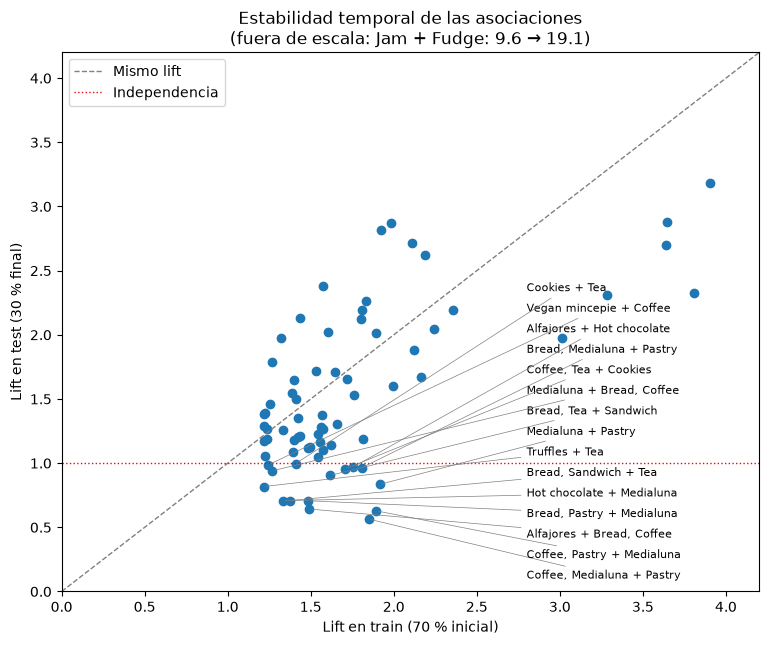

,antecedent,consequent,lift,lift_test
263,"Coffee, Medialuna",Pastry,1.85,0.56
262,"Coffee, Pastry",Medialuna,1.89,0.63
7,Alfajores,"Bread, Coffee",1.49,0.64
120,"Bread, Pastry",Medialuna,1.48,0.71
342,Hot chocolate,Medialuna,1.33,0.71
135,"Bread, Sandwich",Tea,1.37,0.71
380,Truffles,Tea,1.22,0.82
359,Medialuna,Pastry,1.92,0.84
134,"Bread, Tea",Sandwich,1.62,0.90
73,Medialuna,"Bread, Coffee",1.27,0.94


In [44]:
train_rules = mine_rules(train, ANALYSIS_SUPPORT, algorithms[best_algorithm])
train_pairs = collapse_directions(train_rules[train_rules['lift'] >= USEFUL_LIFT])
train_pairs['lift_test'] = [pair_lift(test, a, c) for a, c in zip(train_pairs['antecedents'], train_pairs['consequents'])]

print(f'Train: {basket_datetime.min():%d-%m-%Y} -> {cutoff:%d-%m-%Y} ({len(train)} baskets)')
print(f'Test:  {cutoff:%d-%m-%Y} -> {basket_datetime.max():%d-%m-%Y} ({len(test)} baskets)')
print(f'Associations found in train (lift >= {USEFUL_LIFT}): {len(train_pairs)}')
print(f"  still positive in test (lift > 1): {(train_pairs['lift_test'] > 1).sum()}")
print(f"  still useful in test (lift >= {USEFUL_LIFT}): {(train_pairs['lift_test'] >= USEFUL_LIFT).sum()}")
print(f"  not computable in test (item not sold): {train_pairs['lift_test'].isna().sum()}")

# A few associations of very rare items reach lifts far above the rest; they are listed in the title instead
AXIS_LIMIT = 4.2
in_range = (train_pairs['lift'] <= AXIS_LIMIT) & (train_pairs['lift_test'] <= AXIS_LIMIT)
out_of_range = train_pairs[~in_range & train_pairs['lift_test'].notna()]

plt.figure(figsize=(9, 7))
plt.scatter(train_pairs.loc[in_range, 'lift'], train_pairs.loc[in_range, 'lift_test'])
unstable = train_pairs[train_pairs['lift_test'] < 1].sort_values('lift_test').reset_index(drop=True)
label_x = AXIS_LIMIT - 1.4
for i, row in unstable.iterrows():
    plt.annotate(f"{row['antecedent']} + {row['consequent']}", (row['lift'], row['lift_test']),
                 xytext=(label_x, 0.1 + 0.16 * i), fontsize=8,
                 arrowprops={'arrowstyle': '-', 'color': 'gray', 'linewidth': 0.5})
plt.plot([0, AXIS_LIMIT], [0, AXIS_LIMIT], linestyle='--', color='gray', linewidth=1, label='Mismo lift')
plt.axhline(1, linestyle=':', color='red', linewidth=1, label='Independencia')
plt.xlim(0, AXIS_LIMIT)
plt.ylim(0, AXIS_LIMIT)
plt.xlabel('Lift en train (70 % inicial)')
plt.ylabel('Lift en test (30 % final)')
outliers_note = '; '.join(f"{r['antecedent']} + {r['consequent']}: {r['lift']:.1f} → {r['lift_test']:.1f}"
                          for _, r in out_of_range.iterrows())
plt.title('Estabilidad temporal de las asociaciones'
          + (f'\n(fuera de escala: {outliers_note})' if outliers_note else ''))
plt.legend()
plt.show()

with pd.option_context('display.max_rows', 100):
    display(train_pairs[['antecedent', 'consequent', 'lift', 'lift_test']].sort_values('lift_test').round(2))

In [45]:
not_found_in_train = collapse_directions(positive)
not_found_in_train = not_found_in_train[~not_found_in_train['pair'].isin(set(train_pairs['pair']))].copy()
not_found_in_train['n_train'] = [int((basket_mask(train, a) & basket_mask(train, c)).sum())
                                 for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
not_found_in_train['lift_train'] = [pair_lift(train, a, c) for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
not_found_in_train['lift_test'] = [pair_lift(test, a, c) for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
print(f'Minimum baskets required in train: {int(np.ceil(ANALYSIS_SUPPORT * len(train)))}')
not_found_in_train[['antecedent', 'consequent', 'n_train', 'lift_train', 'lift_test']].round(2)

Minimum baskets required in train: 20


,antecedent,consequent,n_train,lift_train,lift_test
292,"Coffee, Soup",Sandwich,16,2.77,3.30
296,Soup,"Coffee, Sandwich",16,2.50,2.68
187,Jammie Dodgers,Cake,16,2.37,1.90
329,Toast,"Coffee, Tea",18,1.92,1.98
168,Juice,"Cake, Coffee",16,1.61,1.86
164,"Coffee, Juice",Cake,16,1.59,1.84
384,Spanish Brunch,Tea,15,2.04,1.70
207,Chicken Stew,Tea,14,1.83,1.62
231,Extra Salami or Feta,Coffee,13,1.73,1.62
386,Tiffin,Tea,17,2.51,1.15


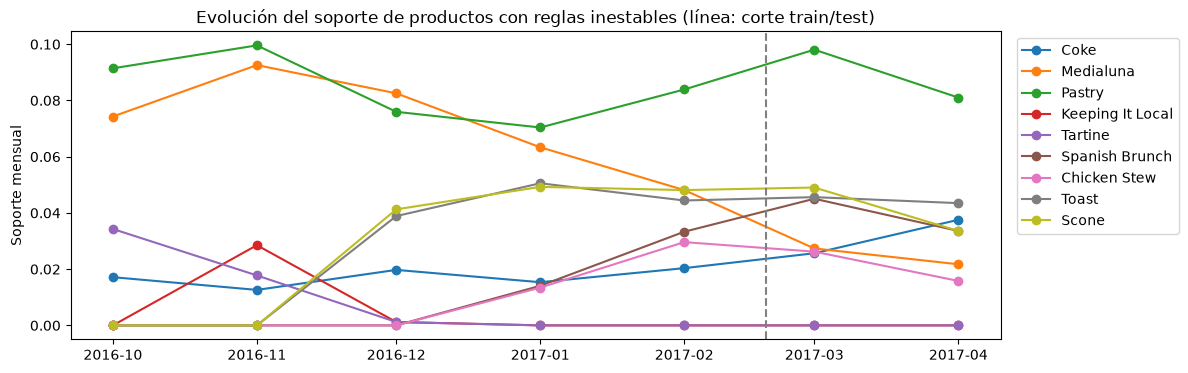

In [46]:
TRACKED_ITEMS = ['Coke', 'Medialuna', 'Pastry', 'Keeping It Local', 'Tartine', 'Spanish Brunch', 'Chicken Stew', 'Toast', 'Scone']
basket_month = basket_datetime.dt.to_period('M').dt.to_timestamp().to_numpy()
monthly_support = df[TRACKED_ITEMS].groupby(basket_month).mean()

plt.figure(figsize=(12, 4))
for item in TRACKED_ITEMS:
    plt.plot(monthly_support.index, monthly_support[item], marker='o', label=item)
plt.axvline(cutoff, linestyle='--', color='gray')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.ylabel('Soporte mensual')
plt.title('Evolución del soporte de productos con reglas inestables (línea: corte train/test)')
plt.show()

Parece que hemos encontrado un núcleo estable. De las 75 asociaciones encontradas en train, 58 siguen siendo positivas en test y 46 mantienen lift ≥ 1.2, sobre todo las del menú de mediodía (Coke + Sandwich, 3.90 → 3.19) y las de bebida + dulce (Hot chocolate + Cake, 1.81 → 2.19). Algunas reglas desaparecen dependiendo del mes, como las de Medialuna (Medialuna + Pastry, 1.92 → 0.84), cuyo soporte mensual cae del 9 % en noviembre al 2 % en abril. Otros productos solo se venden durante parte del periodo (Keeping It Local en noviembre; Spanish Brunch o Chicken Stew a partir de enero), así que sus reglas no se pueden comprobar en test o no llegan al soporte mínimo en train. Esto tiene sentido y abre la puerta a un análisis más profundo donde no solo se tengan en cuenta los periodos del día sino también los meses del año (estudiar la demanda según la estación).

Parece que muchas de las reglas que encontramos sí tienen cierta caducidad. Con más información podríamos intentar averiguar si es una caducidad constante o periódica (no podemos estudiarlo por la falta de fechas: necesitaríamos varios años). La primera nos obligaría a recalcular las reglas cada cierto tiempo, mientras que la segunda nos permitiría calcularlas una vez para cada momento del año y mantenerlas durante muchos años.

*Cautela:* es esperable que los lifts bajen algo en test, porque las reglas se eligieron por tener un lift alto en train. Además, los lifts de test calculados sobre pocas cestas no son fiables: Jam + Fudge pasa de 9.64 a 19.05 con solo 2 cestas en test.

#### 4.7 Conclusiones
Las relaciones más fuertes encontradas entre productos se basan en momentos de consumo como el menú del mediodía. Se pueden crear packs o combos con las asociaciones equilibradas, sobre todo las que tengan un gran solapamiento (Kulczynski alto): Cake + Tea, Sandwich + Tea, etc. Para otras tareas, como la recomendación, se podrían usar las reglas desequilibradas, como Coke → Sandwich.

Se pueden crear surtidos con productos de ventas propias modestas, como Cookies, Juice o Scone, que tienen asociaciones fuertes. Por otro lado, hay combinaciones que se deberían evitar, como Bread, Jam o Fudge con productos de consumo de cafetería.

Todo esto debe contrastarse siempre con la información extra que tengamos (la franja horaria, como vimos en el ejemplo, o el mes, como se vio en el estudio de estabilidad temporal) para evitar caer en trampas estadísticas.

#### Referencias
- Agrawal, R., y Srikant, R. (1994). Fast algorithms for mining association rules. *Proceedings of the 20th International Conference on Very Large Data Bases (VLDB)*, 487–499.
- Benjamini, Y., y Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
- Brin, S., Motwani, R., y Silverstein, C. (1997). Beyond market baskets: Generalizing association rules to correlations. *Proceedings of the 1997 ACM SIGMOD International Conference on Management of Data*, 265–276.
- Han, J., Pei, J., y Yin, Y. (2000). Mining frequent patterns without candidate generation. *Proceedings of the 2000 ACM SIGMOD International Conference on Management of Data*, 1–12.
- Liu, B., Hsu, W., y Ma, Y. (1999). Mining association rules with multiple minimum supports. *Proceedings of the 5th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 337–341.
- Manchanda, P., Ansari, A., y Gupta, S. (1999). The "shopping basket": A model for multicategory purchase incidence decisions. *Marketing Science*, 18(2), 95–114.
- Sarantopoulos, P., Theotokis, A., Pramatari, K., y Doukidis, G. (2016). Shopping missions: An analytical method for the identification of shopper need states. *Journal of Business Research*, 69(3), 1043–1052. https://doi.org/10.1016/j.jbusres.2015.08.017
- Savasere, A., Omiecinski, E., y Navathe, S. (1998). Mining for strong negative associations in a large database of customer transactions. *Proceedings of the 14th International Conference on Data Engineering (ICDE)*, 494–502.
- Simpson, E. H. (1951). The interpretation of interaction in contingency tables. *Journal of the Royal Statistical Society: Series B*, 13(2), 238–241.
- Webb, G. I. (2007). Discovering significant patterns. *Machine Learning*, 68(1), 1–33.
- Wu, T., Chen, Y., y Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery*, 21(3), 371–397.
- Zaki, M. J. (2000). Scalable algorithms for association mining. *IEEE Transactions on Knowledge and Data Engineering*, 12(3), 372–390.